In [1]:
!pip install kagglehub

import kagglehub

# Download the latest version of the ETT small dataset
path = kagglehub.dataset_download("alaaelmor/ettsmall")

print("Path to dataset files:", path)

100%|██████████| 3.89M/3.89M [00:00<00:00, 152MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/alaaelmor/ettsmall/versions/1


In [2]:
import os
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
import kagglehub

# 1. Download dataset using kagglehub
path = kagglehub.dataset_download("alaaelmor/ettsmall")

# 2. Define PyTorch Tabular Dataset Class for ETT
class ETTTabularDataset(Dataset):
    def __init__(self, data_path, file_name="ETTh1.csv", target_col="OT", seq_len=24, pred_len=12):
        full_path = os.path.join(data_path, file_name)
        df = pd.read_csv(full_path)

        # Parse dates and extract features
        df['date'] = pd.to_datetime(df['date'])

        # Numerical feature columns (excluding date)
        self.feature_cols = [c for c in df.columns if c != 'date']
        self.target_col = target_col

        # Convert to float32 PyTorch tensors
        self.data = torch.tensor(df[self.feature_cols].values, dtype=torch.float32)
        self.target_idx = self.feature_cols.index(target_col)

        self.seq_len = seq_len
        self.pred_len = pred_len

    def __len__(self):
        return len(self.data) - self.seq_len - self.pred_len + 1

    def __getitem__(self, idx):
        # Lookback window (x) and prediction window (y)
        x = self.data[idx : idx + self.seq_len]
        y = self.data[idx + self.seq_len : idx + self.seq_len + self.pred_len, self.target_idx]
        return x, y

# 3. Instantiate Dataset and DataLoader
dataset = ETTTabularDataset(data_path=path, file_name="ETTh1.csv", seq_len=24, pred_len=12)
loader = DataLoader(dataset, batch_size=32, shuffle=True)

# 4. Inspect a single batch
X_batch, y_batch = next(iter(loader))

print(f"Input batch shape (Batch, Seq_Len, Features): {X_batch.shape}")
print(f"Target batch shape (Batch, Pred_Len): {y_batch.shape}")

Using Colab cache for faster access to the 'ettsmall' dataset.
Input batch shape (Batch, Seq_Len, Features): torch.Size([32, 24, 7])
Target batch shape (Batch, Pred_Len): torch.Size([32, 12])


In [3]:
import os
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
import kagglehub

# 1. Download dataset using kagglehub
path = kagglehub.dataset_download("alaaelmor/ettsmall")

# 2. Define PyTorch Tabular Dataset Class for ETT
class ETTTabularDataset(Dataset):
    def __init__(self, data_path, file_name="ETTh1.csv", target_col="OT", seq_len=24, pred_len=12):
        full_path = os.path.join(data_path, file_name)
        df = pd.read_csv(full_path)

        # Parse dates and extract features
        df['date'] = pd.to_datetime(df['date'])

        # Numerical feature columns (attributes)
        self.feature_cols = [c for c in df.columns if c != 'date']
        self.target_col = target_col

        # Convert to float32 PyTorch tensors
        self.data = torch.tensor(df[self.feature_cols].values, dtype=torch.float32)
        self.target_idx = self.feature_cols.index(target_col)

        self.seq_len = seq_len
        self.pred_len = pred_len

    def __len__(self):
        return len(self.data) - self.seq_len - self.pred_len + 1

    def __getitem__(self, idx):
        # Lookback window (x) and prediction window (y)
        x = self.data[idx : idx + self.seq_len]
        y = self.data[idx + self.seq_len : idx + self.seq_len + self.pred_len, self.target_idx]
        return x, y

# 3. Instantiate Dataset and DataLoader
dataset = ETTTabularDataset(data_path=path, file_name="ETTh1.csv", seq_len=24, pred_len=12)
loader = DataLoader(dataset, batch_size=32, shuffle=True)

# 4. Print Attributes and Records Information
print("--- ATTRIBUTES & RECORDS INFO ---")
print(f"Attributes ({len(dataset.feature_cols)} features): {dataset.feature_cols}")
print(f"Total Raw CSV Rows: {dataset.data.shape[0]}")
print(f"Total Valid Sliding-Window Records: {len(dataset)}")

# 5. Inspect a single batch
X_batch, y_batch = next(iter(loader))

print("\n--- BATCH SHAPES ---")
print(f"Input batch shape (Batch, Seq_Len, Features): {X_batch.shape}")
print(f"Target batch shape (Batch, Pred_Len): {y_batch.shape}")

Using Colab cache for faster access to the 'ettsmall' dataset.
--- ATTRIBUTES & RECORDS INFO ---
Attributes (7 features): ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
Total Raw CSV Rows: 17420
Total Valid Sliding-Window Records: 17385

--- BATCH SHAPES ---
Input batch shape (Batch, Seq_Len, Features): torch.Size([32, 24, 7])
Target batch shape (Batch, Pred_Len): torch.Size([32, 12])


In [4]:
import os
import pandas as pd
import kagglehub

# 1. Download dataset using kagglehub
path = kagglehub.dataset_download("alaaelmor/ettsmall")

# 2. Read the full dataset into a pandas DataFrame
file_path = os.path.join(path, "ETTh1.csv")
df = pd.read_csv(file_path)

# 3. Print Attributes and Total Records
print("--- DATASET SUMMARY ---")
print(f"Total Attributes/Columns ({len(df.columns)}): {list(df.columns)}")
print(f"Total Records/Rows: {len(df)}")
print("------------------------\n")

# 4. Display option to unlock seeing all columns in pandas output
pd.set_option('display.max_columns', None)

# 5. Display the full interactive table in Google Colab
display(df)

Using Colab cache for faster access to the 'ettsmall' dataset.
--- DATASET SUMMARY ---
Total Attributes/Columns (8): ['date', 'HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
Total Records/Rows: 17420
------------------------



,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2,2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
3,2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
4,2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000
...,...,...,...,...,...,...,...,...
17415,2018-06-26 15:00:00,-1.674,3.550,-5.615,2.132,3.472,1.523,10.904000
17416,2018-06-26 16:00:00,-5.492,4.287,-9.132,2.274,3.533,1.675,11.044000
17417,2018-06-26 17:00:00,2.813,3.818,-0.817,2.097,3.716,1.523,10.271000
17418,2018-06-26 18:00:00,9.243,3.818,5.472,2.097,3.655,1.432,9.778000


In [5]:
import os
import pandas as pd
import kagglehub

# 1. Download the full ETT small dataset folder via kagglehub
path = kagglehub.dataset_download("alaaelmor/ettsmall")

# 2. List all available ETT tables downloaded in the path
files = sorted([f for f in os.listdir(path) if f.endswith('.csv')])
print(f"Available ETT files in path: {files}\n")

# 3. Load all tables into a dictionary of pandas DataFrames
ett_tables = {file: pd.read_csv(os.path.join(path, file)) for file in files}

# 4. Print summaries for all tables (ETTh1, ETTh2, ETTm1, ETTm2)
for file_name, df in ett_tables.items():
    print(f"=== {file_name} ===")
    print(f"Attributes ({len(df.columns)}): {list(df.columns)}")
    print(f"Total Records: {len(df)}")
    print("-" * 30)

# 5. Access and display full tables specifically
df_etth1 = ett_tables['ETTh1.csv']
df_etth2 = ett_tables['ETTh2.csv']

# Display ETTh1 table in Colab
print("\n--- Displaying ETTh1 ---")
display(df_etth1)

# Display ETTh2 table in Colab
print("\n--- Displaying ETTh2 ---")
display(df_etth2)

Using Colab cache for faster access to the 'ettsmall' dataset.
Available ETT files in path: ['ETTh1.csv', 'ETTh2.csv', 'ETTm1.csv', 'ETTm2.csv']

=== ETTh1.csv ===
Attributes (8): ['date', 'HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
Total Records: 17420
------------------------------
=== ETTh2.csv ===
Attributes (8): ['date', 'HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
Total Records: 17420
------------------------------
=== ETTm1.csv ===
Attributes (8): ['date', 'HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
Total Records: 69680
------------------------------
=== ETTm2.csv ===
Attributes (8): ['date', 'HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
Total Records: 69680
------------------------------

--- Displaying ETTh1 ---


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2,2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
3,2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
4,2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000
...,...,...,...,...,...,...,...,...
17415,2018-06-26 15:00:00,-1.674,3.550,-5.615,2.132,3.472,1.523,10.904000
17416,2018-06-26 16:00:00,-5.492,4.287,-9.132,2.274,3.533,1.675,11.044000
17417,2018-06-26 17:00:00,2.813,3.818,-0.817,2.097,3.716,1.523,10.271000
17418,2018-06-26 18:00:00,9.243,3.818,5.472,2.097,3.655,1.432,9.778000



--- Displaying ETTh2 ---


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,41.130001,12.481,36.535999,9.355,4.424,1.311,38.661999
1,2016-07-01 01:00:00,37.528000,10.136,33.936001,7.532,4.435,1.215,37.124001
2,2016-07-01 02:00:00,37.946999,11.309,35.330002,9.007,2.100,0.000,36.465000
3,2016-07-01 03:00:00,38.952000,11.895,35.543999,9.436,3.380,1.215,33.608501
4,2016-07-01 04:00:00,38.113998,11.476,35.410000,9.623,2.036,0.000,31.850500
...,...,...,...,...,...,...,...,...
17415,2018-06-26 15:00:00,39.202999,11.392,49.644001,11.929,-10.331,-1.258,47.084999
17416,2018-06-26 16:00:00,38.113998,10.974,48.759998,11.366,-10.331,-1.290,48.183498
17417,2018-06-26 17:00:00,39.622002,10.974,50.609001,11.661,-11.557,-1.418,48.183498
17418,2018-06-26 18:00:00,43.643002,13.403,54.737000,13.778,-10.299,-1.418,46.865501


Using Colab cache for faster access to the 'ettsmall' dataset.


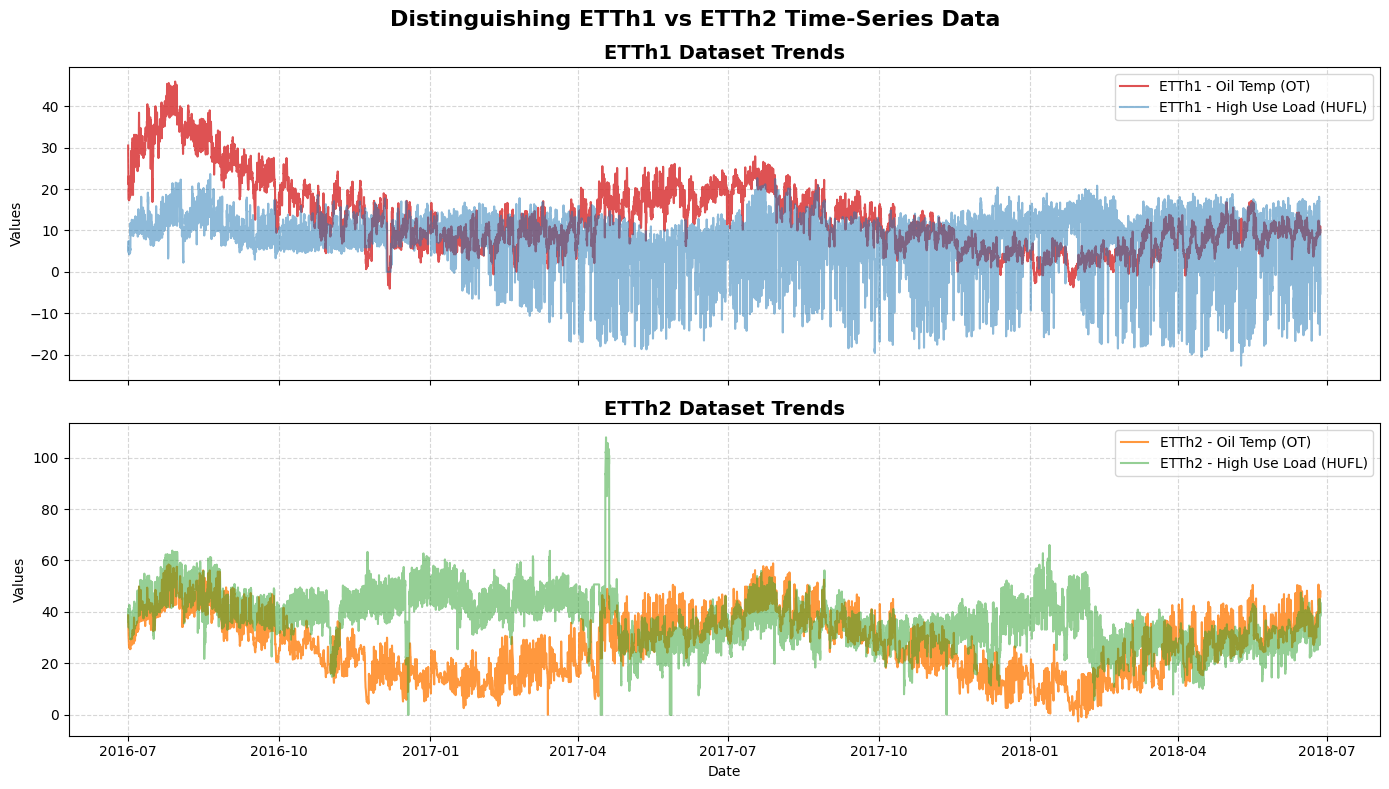

In [6]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

# 1. Download dataset using kagglehub
path = kagglehub.dataset_download("alaaelmor/ettsmall")

# 2. Load ETTh1 and ETTh2 into DataFrames
df_h1 = pd.read_csv(os.path.join(path, "ETTh1.csv"))
df_h2 = pd.read_csv(os.path.join(path, "ETTh2.csv"))

# Convert date column to datetime
df_h1['date'] = pd.to_datetime(df_h1['date'])
df_h2['date'] = pd.to_datetime(df_h2['date'])

# 3. Create comparison graph
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Plot ETTh1 Target (OT) & Load (HUFL)
axes[0].plot(df_h1['date'], df_h1['OT'], label='ETTh1 - Oil Temp (OT)', color='tab:red', alpha=0.8)
axes[0].plot(df_h1['date'], df_h1['HUFL'], label='ETTh1 - High Use Load (HUFL)', color='tab:blue', alpha=0.5)
axes[0].set_title("ETTh1 Dataset Trends", fontsize=14, fontweight='bold')
axes[0].set_ylabel("Values")
axes[0].legend(loc="upper right")
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot ETTh2 Target (OT) & Load (HUFL)
axes[1].plot(df_h2['date'], df_h2['OT'], label='ETTh2 - Oil Temp (OT)', color='tab:orange', alpha=0.8)
axes[1].plot(df_h2['date'], df_h2['HUFL'], label='ETTh2 - High Use Load (HUFL)', color='tab:green', alpha=0.5)
axes[1].set_title("ETTh2 Dataset Trends", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Values")
axes[1].legend(loc="upper right")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Distinguishing ETTh1 vs ETTh2 Time-Series Data", fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

Using Colab cache for faster access to the 'ettsmall' dataset.


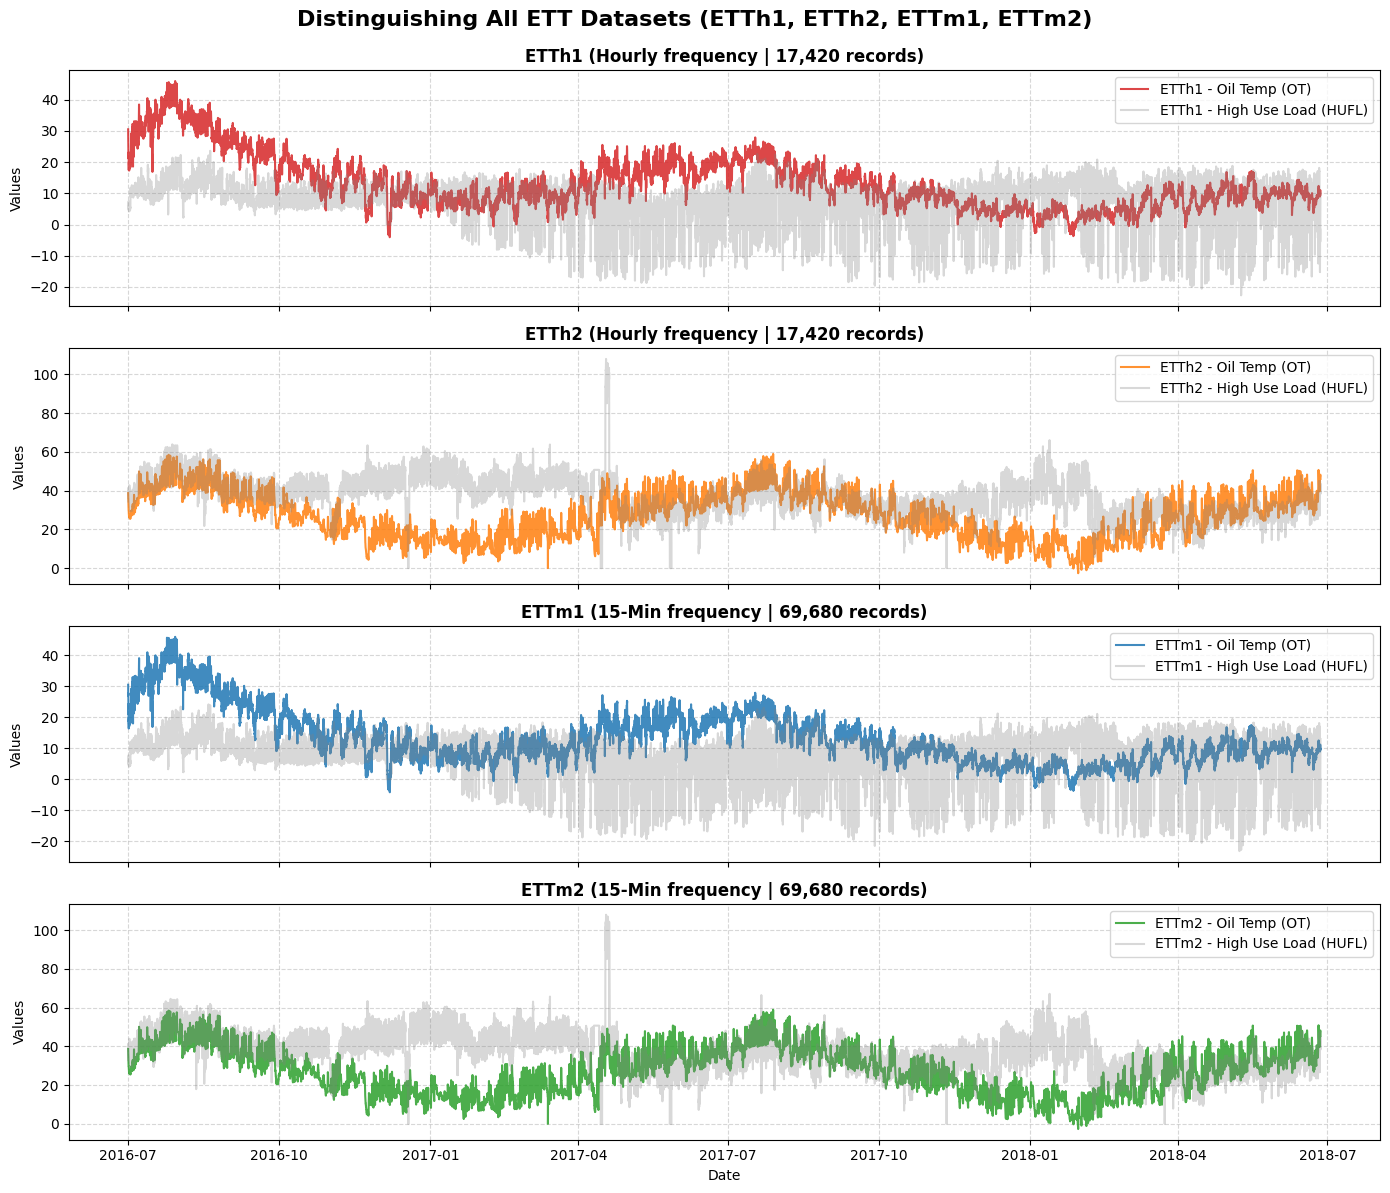

In [7]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

# 1. Download dataset using kagglehub
path = kagglehub.dataset_download("alaaelmor/ettsmall")

# 2. Load all 4 CSV datasets into DataFrames
files = ["ETTh1.csv", "ETTh2.csv", "ETTm1.csv", "ETTm2.csv"]
dfs = {f.split('.')[0]: pd.read_csv(os.path.join(path, f)) for f in files}

# Convert date columns to datetime
for name, df in dfs.items():
    df['date'] = pd.to_datetime(df['date'])

# 3. Plot all 4 datasets to distinguish them
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

colors = {'ETTh1': 'tab:red', 'ETTh2': 'tab:orange', 'ETTm1': 'tab:blue', 'ETTm2': 'tab:green'}

for i, (name, df) in enumerate(dfs.items()):
    axes[i].plot(df['date'], df['OT'], label=f"{name} - Oil Temp (OT)", color=colors[name], alpha=0.85)
    axes[i].plot(df['date'], df['HUFL'], label=f"{name} - High Use Load (HUFL)", color='gray', alpha=0.3)

    # Title showing sampling type and total rows
    freq = "Hourly" if 'h' in name else "15-Min"
    axes[i].set_title(f"{name} ({freq} frequency | {len(df):,} records)", fontsize=12, fontweight='bold')
    axes[i].set_ylabel("Values")
    axes[i].legend(loc="upper right")
    axes[i].grid(True, linestyle='--', alpha=0.5)

axes[-1].set_xlabel("Date")
plt.suptitle("Distinguishing All ETT Datasets (ETTh1, ETTh2, ETTm1, ETTm2)", fontsize=16, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

Using Colab cache for faster access to the 'ettsmall' dataset.


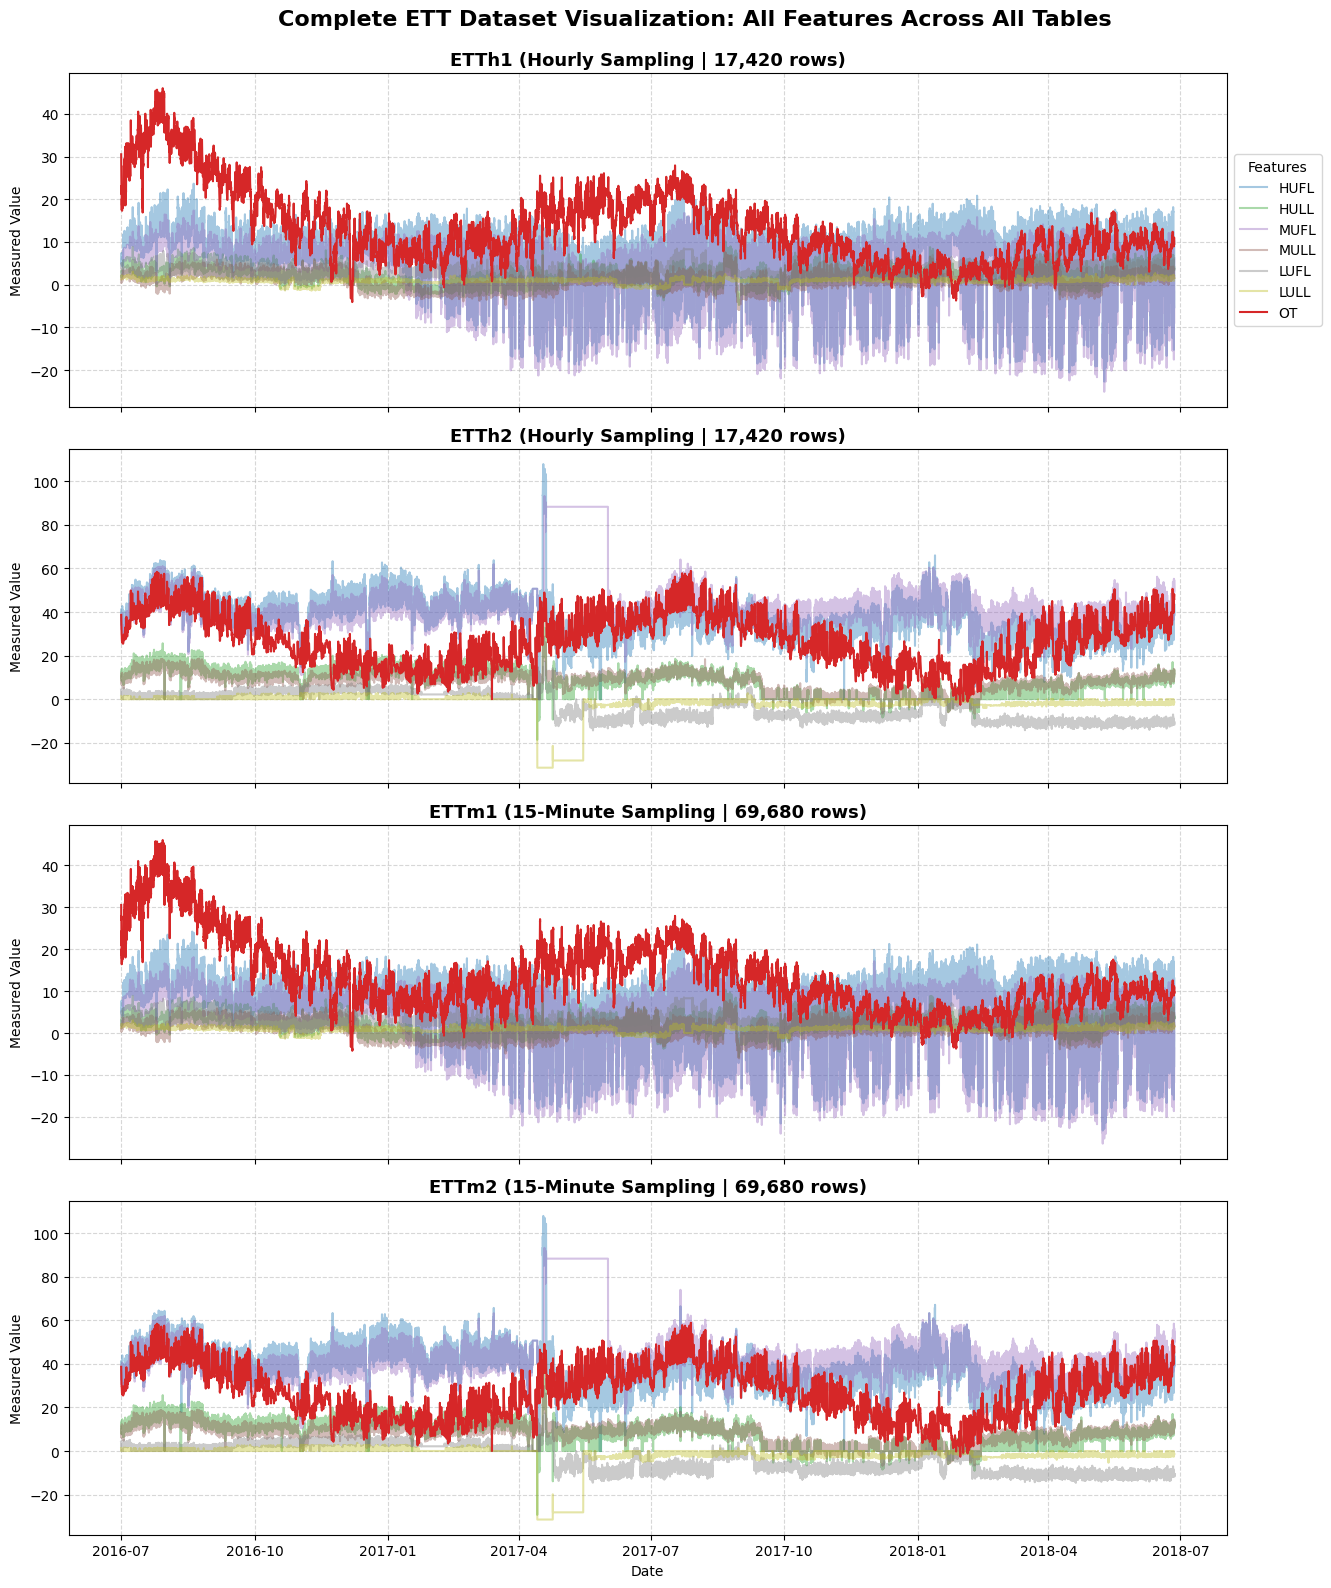

In [8]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

# 1. Download dataset using kagglehub
path = kagglehub.dataset_download("alaaelmor/ettsmall")

# 2. Load all 4 datasets into DataFrames
files = ["ETTh1.csv", "ETTh2.csv", "ETTm1.csv", "ETTm2.csv"]
dfs = {f.split('.')[0]: pd.read_csv(os.path.join(path, f)) for f in files}

# Convert date columns to datetime
for df in dfs.values():
    df['date'] = pd.to_datetime(df['date'])

# 3. List of features to plot (All except 'date')
features_to_plot = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
colors = ['tab:blue', 'tab:green', 'tab:purple', 'tab:brown', 'tab:gray', 'tab:olive', 'tab:red']

# 4. Create a 4x1 grid of plots (one for each dataset)
fig, axes = plt.subplots(4, 1, figsize=(14, 16), sharex=True)

# Iterate through datasets and plot all features on their respective subplot
for i, (name, df) in enumerate(dfs.items()):
    ax = axes[i]
    freq_desc = "Hourly" if 'h' in name else "15-Minute"
    ax.set_title(f"{name} ({freq_desc} Sampling | {len(df):,} rows)", fontsize=13, fontweight='bold')

    # Plot all 7 features on the same y-axis for this dataset
    for f_idx, feature in enumerate(features_to_plot):
        alpha_val = 1.0 if feature == 'OT' else 0.4  # Highlight 'OT'
        ax.plot(df['date'], df[feature], label=feature, color=colors[f_idx], alpha=alpha_val)

    ax.set_ylabel("Measured Value")
    ax.grid(True, linestyle='--', alpha=0.5)

    # Place legend once on the right-hand side
    if i == 0:
        ax.legend(title="Features", loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)

# 5. Final graph labels and display
axes[-1].set_xlabel("Date")
plt.suptitle("Complete ETT Dataset Visualization: All Features Across All Tables", fontsize=16, fontweight='bold', y=0.99)
plt.tight_layout()
plt.subplots_adjust(right=0.88, top=0.95) # Adjust right margin for the legend
plt.show()

Using Colab cache for faster access to the 'ettsmall' dataset.


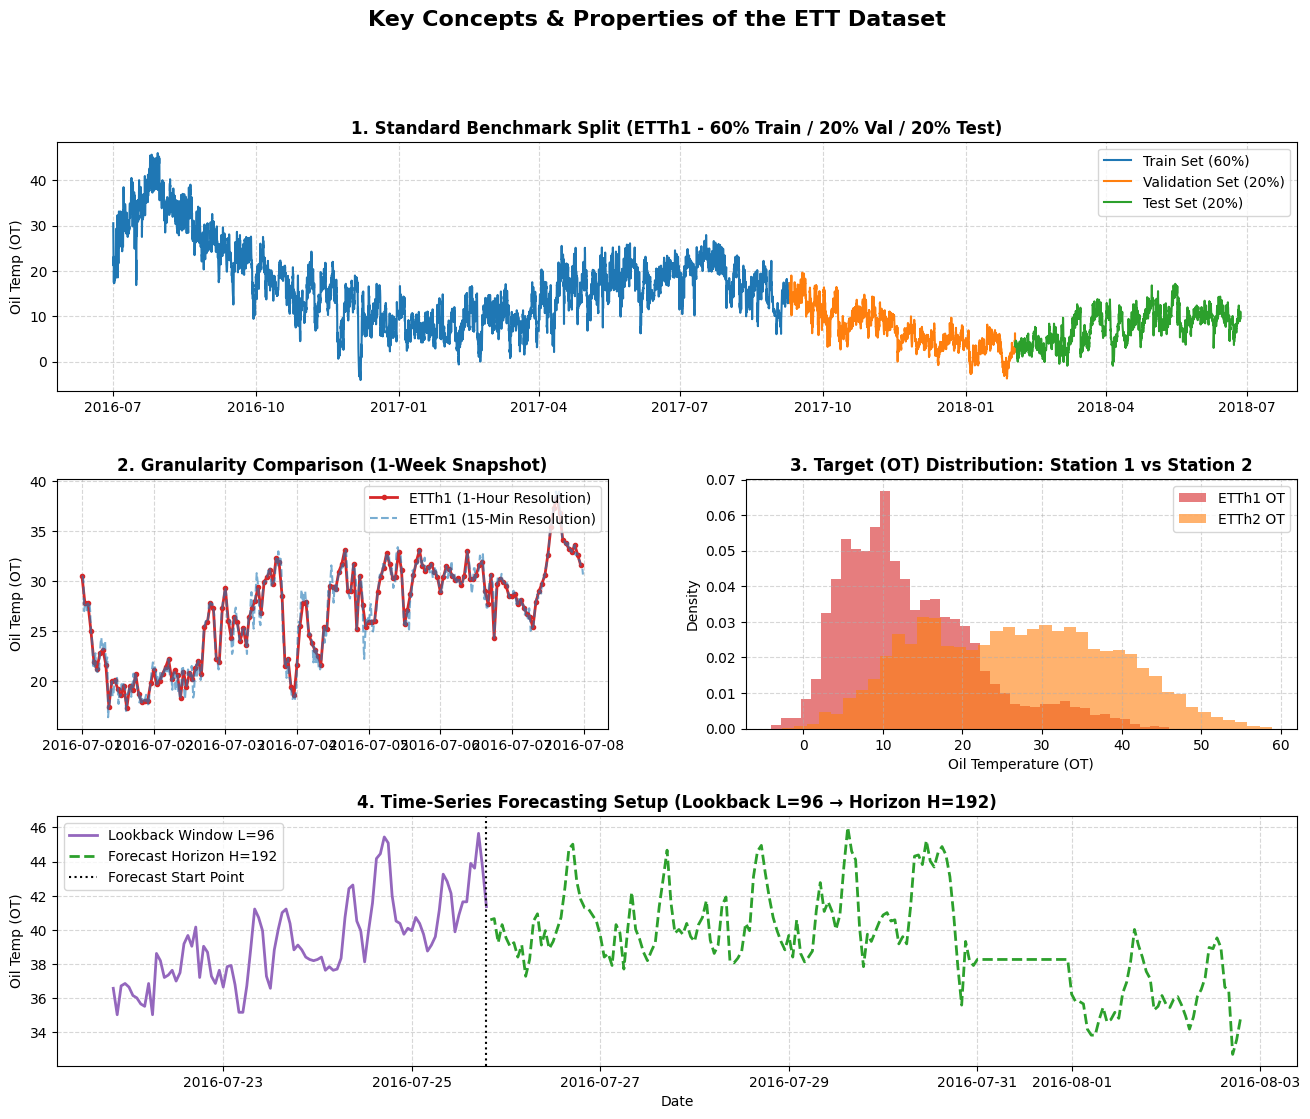

In [9]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import kagglehub

# 1. Download dataset using kagglehub
path = kagglehub.dataset_download("alaaelmor/ettsmall")

# Load ETTh1 and ETTm1 for comparison
df_h1 = pd.read_csv(os.path.join(path, "ETTh1.csv"))
df_m1 = pd.read_csv(os.path.join(path, "ETTm1.csv"))

df_h1['date'] = pd.to_datetime(df_h1['date'])
df_m1['date'] = pd.to_datetime(df_m1['date'])

# Set up figure grid
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(3, 2, hspace=0.35, wspace=0.25)

# ---------------------------------------------------------
# GRAPH 1: Standard Chronological Train / Val / Test Split (60-20-20)
# ---------------------------------------------------------
ax1 = fig.add_subplot(gs[0, :])
n = len(df_h1)
train_end, val_end = int(n * 0.6), int(n * 0.8)

ax1.plot(df_h1['date'][:train_end], df_h1['OT'][:train_end], color='tab:blue', label='Train Set (60%)')
ax1.plot(df_h1['date'][train_end:val_end], df_h1['OT'][train_end:val_end], color='tab:orange', label='Validation Set (20%)')
ax1.plot(df_h1['date'][val_end:], df_h1['OT'][val_end:], color='tab:green', label='Test Set (20%)')

ax1.set_title("1. Standard Benchmark Split (ETTh1 - 60% Train / 20% Val / 20% Test)", fontsize=12, fontweight='bold')
ax1.set_ylabel("Oil Temp (OT)")
ax1.legend(loc="upper right")
ax1.grid(True, linestyle='--', alpha=0.5)

# ---------------------------------------------------------
# GRAPH 2: Sampling Frequency Comparison (Hourly vs 15-Min)
# ---------------------------------------------------------
ax2 = fig.add_subplot(gs[1, 0])
sample_days = 7 * 24 # 1 week view
sample_h1 = df_h1.iloc[:sample_days]
sample_m1 = df_m1.iloc[:sample_days * 4] # 4x sampling rate

ax2.plot(sample_h1['date'], sample_h1['OT'], label='ETTh1 (1-Hour Resolution)', color='tab:red', linewidth=2, marker='o', markersize=3)
ax2.plot(sample_m1['date'], sample_m1['OT'], label='ETTm1 (15-Min Resolution)', color='tab:blue', alpha=0.6, linestyle='--')

ax2.set_title("2. Granularity Comparison (1-Week Snapshot)", fontsize=12, fontweight='bold')
ax2.set_ylabel("Oil Temp (OT)")
ax2.legend(loc="upper right")
ax2.grid(True, linestyle='--', alpha=0.5)

# ---------------------------------------------------------
# GRAPH 3: Target Feature Distribution Across Stations
# ---------------------------------------------------------
ax3 = fig.add_subplot(gs[1, 1])
df_h2 = pd.read_csv(os.path.join(path, "ETTh2.csv"))

ax3.hist(df_h1['OT'], bins=40, color='tab:red', alpha=0.6, label='ETTh1 OT', density=True)
ax3.hist(df_h2['OT'], bins=40, color='tab:orange', alpha=0.6, label='ETTh2 OT', density=True)

ax3.set_title("3. Target (OT) Distribution: Station 1 vs Station 2", fontsize=12, fontweight='bold')
ax3.set_xlabel("Oil Temperature (OT)")
ax3.set_ylabel("Density")
ax3.legend(loc="upper right")
ax3.grid(True, linestyle='--', alpha=0.5)

# ---------------------------------------------------------
# GRAPH 4: Lookback Window vs Horizon Task Setup
# ---------------------------------------------------------
ax4 = fig.add_subplot(gs[2, :])
seq_len, pred_len = 96, 192
sample_idx = 500

lookback = df_h1.iloc[sample_idx : sample_idx + seq_len]
horizon = df_h1.iloc[sample_idx + seq_len : sample_idx + seq_len + pred_len]

ax4.plot(lookback['date'], lookback['OT'], label=f'Lookback Window L={seq_len}', color='tab:purple', linewidth=2)
ax4.plot(horizon['date'], horizon['OT'], label=f'Forecast Horizon H={pred_len}', color='tab:green', linewidth=2, linestyle='--')
ax4.axvline(x=lookback['date'].iloc[-1], color='black', linestyle=':', label='Forecast Start Point')

ax4.set_title("4. Time-Series Forecasting Setup (Lookback L=96 → Horizon H=192)", fontsize=12, fontweight='bold')
ax4.set_ylabel("Oil Temp (OT)")
ax4.set_xlabel("Date")
ax4.legend(loc="upper left")
ax4.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Key Concepts & Properties of the ETT Dataset", fontsize=16, fontweight='bold', y=0.99)
plt.show()

FEDFORMER

Using Colab cache for faster access to the 'ettsmall' dataset.
Path to dataset files: /kaggle/input/ettsmall
Using dataset file: /kaggle/input/ettsmall/ETTh2.csv

Training FEDformer on cuda...
Epoch [01/03] | Train MSE: 0.2844 | Val MSE: 0.4217
Epoch [02/03] | Train MSE: 0.1362 | Val MSE: 0.4204
Epoch [03/03] | Train MSE: 0.1078 | Val MSE: 0.4153


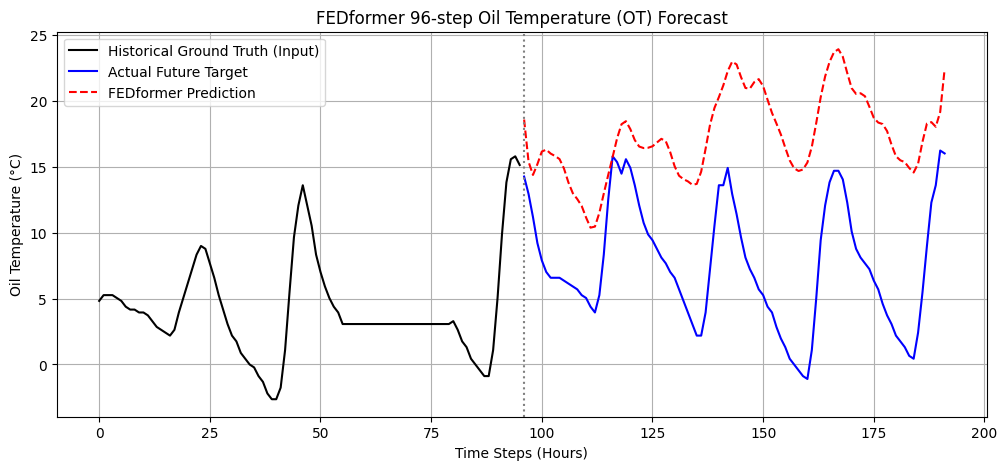

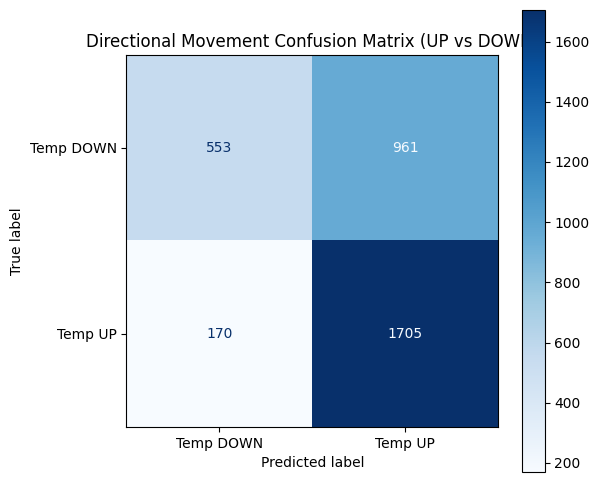

In [10]:
import os
import glob
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# =====================================================================
# 1. DOWNLOAD ETT SMALL DATASET VIA KAGGLEHUB
# =====================================================================
import kagglehub

# Download the latest version of the ETT small dataset
path = kagglehub.dataset_download("alaaelmor/ettsmall")

print("Path to dataset files:", path)

# Locate CSV file inside the downloaded path (e.g., ETTh1.csv)
csv_files = glob.glob(os.path.join(path, "*.csv"))
csv_path = csv_files[0] if csv_files else os.path.join(path, "ETTh1.csv")
print(f"Using dataset file: {csv_path}\n")


# =====================================================================
# 2. DATASET DEFINITION & PREPROCESSING
# =====================================================================
class ETTDataset(Dataset):
    """
    Splits continuous ETT time-series into sliding windows for multi-step forecasting.
    Normalizes dataset based strictly on training set statistics.
    """
    def __init__(self, csv_file, seq_len=96, label_len=48, pred_len=96, mode='train'):
        self.seq_len = seq_len
        self.label_len = label_len
        self.pred_len = pred_len

        df = pd.read_csv(csv_file)
        if 'date' in df.columns:
            df = df.drop(columns=['date'])

        data = df.values.astype(np.float32)

        # Standard train (70%) / val (10%) / test (20%) split
        n = len(data)
        train_end = int(n * 0.7)
        val_end = int(n * 0.8)

        self.scaler = StandardScaler()
        self.scaler.fit(data[:train_end])
        data = self.scaler.transform(data)

        if mode == 'train':
            self.data = data[:train_end]
        elif mode == 'val':
            self.data = data[train_end - seq_len : val_end]
        else:
            self.data = data[val_end - seq_len :]

    def __len__(self):
        return len(self.data) - self.seq_len - self.pred_len + 1

    def __getitem__(self, index):
        s_begin = index
        s_end = s_begin + self.seq_len
        r_begin = s_end - self.label_len
        r_end = r_begin + self.label_len + self.pred_len

        seq_x = self.data[s_begin:s_end]
        seq_y = self.data[r_begin:r_end]

        return torch.tensor(seq_x, dtype=torch.float32), torch.tensor(seq_y, dtype=torch.float32)


# =====================================================================
# 3. FEDFORMER MODULES
# =====================================================================
class MovingAvg(nn.Module):
    """Decomposes time-series into trend and seasonal components."""
    def __init__(self, kernel_size, stride=1):
        super(MovingAvg, self).__init__()
        self.kernel_size = kernel_size
        self.avg = nn.AvgPool1d(kernel_size=kernel_size, stride=stride, padding=0)

    def forward(self, x):
        pad_num = (self.kernel_size - 1) // 2
        front = x[:, 0:1, :].repeat(1, pad_num, 1)
        end = x[:, -1:, :].repeat(1, pad_num, 1)
        x_padded = torch.cat([front, x, end], dim=1).permute(0, 2, 1)

        trend = self.avg(x_padded).permute(0, 2, 1)
        seasonal = x - trend
        return seasonal, trend


class FourierBlock(nn.Module):
    """Frequency Enhanced Block (FEB) using Fast Fourier Transform (rFFT)."""
    def __init__(self, in_channels, out_channels, seq_len, modes=32):
        super(FourierBlock, self).__init__()
        self.modes = modes
        self.weights = nn.Parameter(
            torch.randn(in_channels, out_channels, self.modes, dtype=torch.cfloat) * 0.02
        )

    def forward(self, x):
        B, L, C = x.shape
        x_ft = torch.fft.rfft(x, dim=1)
        out_ft = torch.zeros(B, x_ft.size(1), C, dtype=torch.cfloat, device=x.device)
        modes = min(self.modes, x_ft.size(1))
        out_ft[:, :modes, :] = torch.einsum("bmi,iom->bmo", x_ft[:, :modes, :], self.weights[:, :, :modes])
        x_out = torch.fft.irfft(out_ft, n=L, dim=1)
        return x_out


class FEDformer(nn.Module):
    """FEDformer Long-term Time Series Forecasting Model."""
    def __init__(self, seq_len, label_len, pred_len, enc_in, dec_in, c_out, d_model=64, modes=32):
        super(FEDformer, self).__init__()
        self.seq_len = seq_len
        self.label_len = label_len
        self.pred_len = pred_len

        self.decomp = MovingAvg(kernel_size=25)
        self.enc_embedding = nn.Linear(enc_in, d_model)
        self.dec_embedding = nn.Linear(dec_in, d_model)

        self.fourier_enc = FourierBlock(d_model, d_model, seq_len, modes=modes)
        self.fourier_dec = FourierBlock(d_model, d_model, label_len + pred_len, modes=modes)

        self.projection = nn.Linear(d_model, c_out)
        self.trend_projection = nn.Linear(enc_in, c_out)
        self.cross_attention = nn.MultiheadAttention(d_model, num_heads=4, batch_first=True)
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x_enc, x_dec):
        seasonal_enc, trend_enc = self.decomp(x_enc)
        enc_out = self.enc_embedding(seasonal_enc)
        enc_out = self.fourier_enc(enc_out)

        dec_out = self.dec_embedding(x_dec)
        attended, _ = self.cross_attention(dec_out, enc_out, enc_out)
        dec_out = self.norm(dec_out + attended)
        dec_out = self.fourier_dec(dec_out)
        seasonal_pred = self.projection(dec_out)

        last_trend = trend_enc[:, -1:, :]
        trend_pred = self.trend_projection(last_trend)
        trend_pred = trend_pred.expand(-1, self.label_len + self.pred_len, -1)
        final_out = seasonal_pred + trend_pred
        return final_out[:, -self.pred_len:, :]


# =====================================================================
# 4. TRAINING, FORECAST PLOT & CONFUSION MATRIX
# =====================================================================
def main():
    # Parameters
    SEQ_LEN = 96
    LABEL_LEN = 48
    PRED_LEN = 96
    BATCH_SIZE = 32
    EPOCHS = 3
    LEARNING_RATE = 0.001
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Data Loaders
    train_dataset = ETTDataset(csv_path, SEQ_LEN, LABEL_LEN, PRED_LEN, mode='train')
    val_dataset = ETTDataset(csv_path, SEQ_LEN, LABEL_LEN, PRED_LEN, mode='val')
    test_dataset = ETTDataset(csv_path, SEQ_LEN, LABEL_LEN, PRED_LEN, mode='test')

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    num_features = train_dataset.data.shape[1]

    # Initialize Model, Criterion, Optimizer
    model = FEDformer(
        seq_len=SEQ_LEN, label_len=LABEL_LEN, pred_len=PRED_LEN,
        enc_in=num_features, dec_in=num_features, c_out=num_features
    ).to(DEVICE)

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    # --- Training Loop ---
    print(f"Training FEDformer on {DEVICE}...")
    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_loss = 0.0
        for x_enc, x_y in train_loader:
            x_enc, x_y = x_enc.to(DEVICE), x_y.to(DEVICE)
            zeros = torch.zeros(x_enc.shape[0], PRED_LEN, num_features, device=DEVICE)
            x_dec = torch.cat([x_enc[:, -LABEL_LEN:, :], zeros], dim=1)

            optimizer.zero_grad()
            preds = model(x_enc, x_dec)
            loss = criterion(preds, x_y[:, -PRED_LEN:, :])
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        # Validation Loss
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for x_enc, x_y in val_loader:
                x_enc, x_y = x_enc.to(DEVICE), x_y.to(DEVICE)
                zeros = torch.zeros(x_enc.shape[0], PRED_LEN, num_features, device=DEVICE)
                x_dec = torch.cat([x_enc[:, -LABEL_LEN:, :], zeros], dim=1)
                preds = model(x_enc, x_dec)
                val_loss += criterion(preds, x_y[:, -PRED_LEN:, :]).item()

        print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] | Train MSE: {train_loss / len(train_loader):.4f} | Val MSE: {val_loss / len(val_loader):.4f}")

    # --- Test Set Evaluation ---
    model.eval()
    all_preds, all_targets, all_inputs = [], [], []

    with torch.no_grad():
        for x_enc, x_y in test_loader:
            x_enc, x_y = x_enc.to(DEVICE), x_y.to(DEVICE)
            zeros = torch.zeros(x_enc.shape[0], PRED_LEN, num_features, device=DEVICE)
            x_dec = torch.cat([x_enc[:, -LABEL_LEN:, :], zeros], dim=1)

            preds = model(x_enc, x_dec)
            all_inputs.append(x_enc.cpu().numpy())
            all_preds.append(preds.cpu().numpy())
            all_targets.append(x_y[:, -PRED_LEN:, :].cpu().numpy())

    all_inputs = np.concatenate(all_inputs, axis=0)
    all_preds = np.concatenate(all_preds, axis=0)
    all_targets = np.concatenate(all_targets, axis=0)

    # Inverse Transform Target Feature (OT - Oil Temperature)
    ot_idx = -1
    std_ot = test_dataset.scaler.scale_[ot_idx]
    mean_ot = test_dataset.scaler.mean_[ot_idx]

    pred_ot = all_preds[:, :, ot_idx] * std_ot + mean_ot
    target_ot = all_targets[:, :, ot_idx] * std_ot + mean_ot
    input_ot = all_inputs[:, :, ot_idx] * std_ot + mean_ot

    # --- PLOT 1: FORECAST GRAPH ---
    sample_idx = 0
    plt.figure(figsize=(12, 5))
    plt.plot(range(0, SEQ_LEN), input_ot[sample_idx], label="Historical Ground Truth (Input)", color="black")
    plt.plot(range(SEQ_LEN, SEQ_LEN + PRED_LEN), target_ot[sample_idx], label="Actual Future Target", color="blue")
    plt.plot(range(SEQ_LEN, SEQ_LEN + PRED_LEN), pred_ot[sample_idx], label="FEDformer Prediction", color="red", linestyle="--")
    plt.axvline(x=SEQ_LEN, color="gray", linestyle=":")
    plt.title("FEDformer 96-step Oil Temperature (OT) Forecast")
    plt.xlabel("Time Steps (Hours)")
    plt.ylabel("Oil Temperature (°C)")
    plt.legend()
    plt.grid(True)
    plt.show()

    # --- PLOT 2: DIRECTIONAL MOVEMENT CONFUSION MATRIX ---
    # Direction relative to the last known input value
    last_known = input_ot[:, -1]
    actual_direction = (target_ot[:, -1] > last_known).astype(int)  # 1 = UP, 0 = DOWN
    pred_direction = (pred_ot[:, -1] > last_known).astype(int)

    cm = confusion_matrix(actual_direction, pred_direction)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Temp DOWN", "Temp UP"])

    fig, ax = plt.subplots(figsize=(6, 6))
    disp.plot(cmap=plt.cm.Blues, ax=ax)
    plt.title("Directional Movement Confusion Matrix (UP vs DOWN)")
    plt.show()


if __name__ == "__main__":
    main()

In [11]:
#PATCH TST

Using Colab cache for faster access to the 'ettsmall' dataset.
Path to dataset files: /kaggle/input/ettsmall
Using dataset file: /kaggle/input/ettsmall/ETTh2.csv

Training PatchTST on cuda...
Epoch [01/03] | Train MSE: 0.3075 | Val MSE: 0.2759
Epoch [02/03] | Train MSE: 0.2630 | Val MSE: 0.3003
Epoch [03/03] | Train MSE: 0.2460 | Val MSE: 0.2484


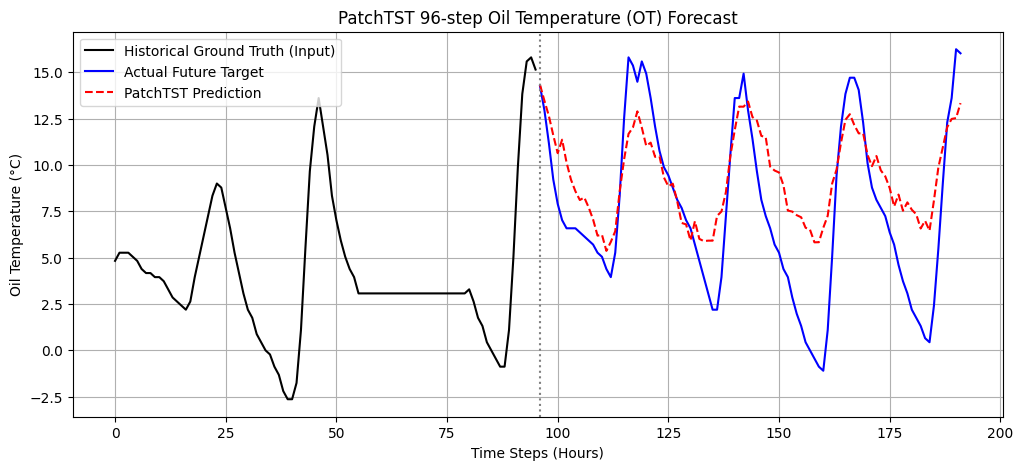

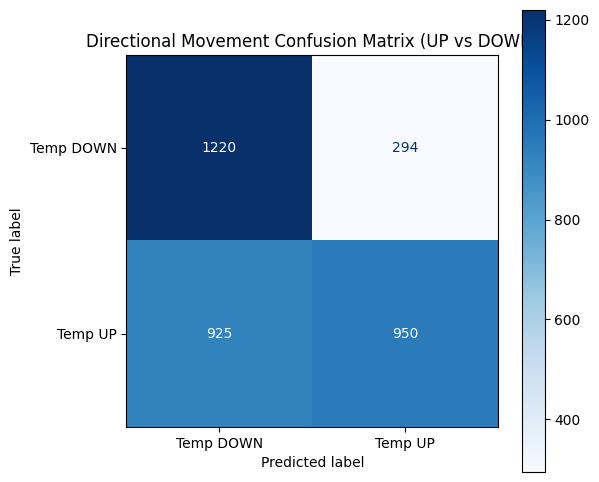

In [12]:
import os
import glob
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# =====================================================================
# 1. DOWNLOAD ETT SMALL DATASET VIA KAGGLEHUB
# =====================================================================
import kagglehub

# Download the latest version of the ETT small dataset
path = kagglehub.dataset_download("alaaelmor/ettsmall")

print("Path to dataset files:", path)

# Locate CSV file inside the downloaded path (e.g., ETTh1.csv)
csv_files = glob.glob(os.path.join(path, "*.csv"))
csv_path = csv_files[0] if csv_files else os.path.join(path, "ETTh1.csv")
print(f"Using dataset file: {csv_path}\n")


# =====================================================================
# 2. DATASET DEFINITION & PREPROCESSING
# =====================================================================
class ETTDataset(Dataset):
    """
    Splits continuous ETT time-series into sliding windows for multi-step forecasting.
    Normalizes dataset based strictly on training set statistics.
    """
    def __init__(self, csv_file, seq_len=96, label_len=48, pred_len=96, mode='train'):
        self.seq_len = seq_len
        self.label_len = label_len
        self.pred_len = pred_len

        df = pd.read_csv(csv_file)
        if 'date' in df.columns:
            df = df.drop(columns=['date'])

        data = df.values.astype(np.float32)

        # Standard train (70%) / val (10%) / test (20%) split
        n = len(data)
        train_end = int(n * 0.7)
        val_end = int(n * 0.8)

        self.scaler = StandardScaler()
        self.scaler.fit(data[:train_end])
        data = self.scaler.transform(data)

        if mode == 'train':
            self.data = data[:train_end]
        elif mode == 'val':
            self.data = data[train_end - seq_len : val_end]
        else:
            self.data = data[val_end - seq_len :]

    def __len__(self):
        return len(self.data) - self.seq_len - self.pred_len + 1

    def __getitem__(self, index):
        s_begin = index
        s_end = s_begin + self.seq_len
        r_begin = s_end - self.label_len
        r_end = r_begin + self.label_len + self.pred_len

        seq_x = self.data[s_begin:s_end]
        seq_y = self.data[r_begin:r_end]

        return torch.tensor(seq_x, dtype=torch.float32), torch.tensor(seq_y, dtype=torch.float32)


# =====================================================================
# 3. PATCHTST ARCHITECTURE COMPONENTS
# =====================================================================
class PatchEmbedding(nn.Module):
    """
    Extracts overlapping local patches from sequence and projects to d_model dimension.
    """
    def __init__(self, patch_len, stride, d_model):
        super(PatchEmbedding, self).__init__()
        self.patch_len = patch_len
        self.stride = stride
        self.projection = nn.Linear(patch_len, d_model)

    def forward(self, x):
        # x shape: [B * C, L]
        # Unfold sequence into patches -> [B * C, num_patches, patch_len]
        x_patched = x.unfold(dimension=-1, size=self.patch_len, step=self.stride)
        out = self.projection(x_patched)  # [B * C, num_patches, d_model]
        return out, x_patched.size(1)


class PositionalEncoding(nn.Module):
    """Adds learnable positional encodings to tokenized patch representations."""
    def __init__(self, d_model, max_len=500):
        super(PositionalEncoding, self).__init__()
        self.pos_embed = nn.Parameter(torch.randn(1, max_len, d_model) * 0.02)

    def forward(self, x):
        # x shape: [B * C, num_patches, d_model]
        num_patches = x.size(1)
        return x + self.pos_embed[:, :num_patches, :]


class PatchTST(nn.Module):
    """
    PatchTST Backbone featuring Channel Independence and Local Patching.
    """
    def __init__(self, seq_len, pred_len, num_features, patch_len=16, stride=8, d_model=64, n_heads=4, n_layers=2, dropout=0.1):
        super(PatchTST, self).__init__()
        if patch_len > seq_len:
          raise ValueError("patch_len cannot exceed seq_len")

        if d_model % n_heads != 0:
          raise ValueError("d_model must be divisible by n_heads")

        self.seq_len = seq_len
        self.pred_len = pred_len
        self.num_features = num_features

        self.patch_embed = PatchEmbedding(patch_len, stride, d_model)
        self.pos_embed = PositionalEncoding(d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=n_heads, dim_feedforward=d_model * 4,
            dropout=dropout, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)

        # Calculate number of patches
        num_patches = int((seq_len - patch_len) / stride) + 1

        # Flattened Linear Projection Head
        self.head = nn.Linear(num_patches * d_model, pred_len)

    def forward(self, x):
        # Input shape: [Batch, Seq_Len, Channels]
        B, L, C = x.shape

        # 1. Channel Independence: Flatten Batch & Channels into single dimension
        # x shape becomes: [B * C, Seq_Len]
        x = x.permute(0, 2, 1).reshape(B * C, L)

        # 2. Patch Extraction & Linear Projection -> [B * C, Num_Patches, d_model]
        enc_in, num_patches = self.patch_embed(x)

        # 3. Add Positional Encodings
        enc_in = self.pos_embed(enc_in)

        # 4. Transformer Attention Representation
        enc_out = self.transformer(enc_in)  # [B * C, Num_Patches, d_model]

        # 5. Flatten Patches and Project to Future Prediction Horizon
        enc_out = enc_out.reshape(B * C, -1)  # [B * C, Num_Patches * d_model]
        dec_out = self.head(enc_out)          # [B * C, Pred_Len]

        # 6. Reshape back to original multivariate channel shape
        out = dec_out.reshape(B, C, self.pred_len).permute(0, 2, 1)  # [B, Pred_Len, C]
        return out


# =====================================================================
# 4. TRAINING, FORECAST PLOT & CONFUSION MATRIX
# =====================================================================
def main():
    # Parameters
    SEQ_LEN = 96
    LABEL_LEN = 48
    PRED_LEN = 96
    BATCH_SIZE = 32
    EPOCHS = 3
    LEARNING_RATE = 0.001
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Data Loaders
    train_dataset = ETTDataset(csv_path, SEQ_LEN, LABEL_LEN, PRED_LEN, mode='train')
    val_dataset = ETTDataset(csv_path, SEQ_LEN, LABEL_LEN, PRED_LEN, mode='val')
    test_dataset = ETTDataset(csv_path, SEQ_LEN, LABEL_LEN, PRED_LEN, mode='test')

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    num_features = train_dataset.data.shape[1]

    # Initialize PatchTST Model, Criterion, Optimizer
    model = PatchTST(
        seq_len=SEQ_LEN,
        pred_len=PRED_LEN,
        num_features=num_features,
        patch_len=16,
        stride=8,
        d_model=64
    ).to(DEVICE)

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    # --- Training Loop ---
    print(f"Training PatchTST on {DEVICE}...")
    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_loss = 0.0
        for x_enc, x_y in train_loader:
            x_enc, x_y = x_enc.to(DEVICE), x_y.to(DEVICE)

            optimizer.zero_grad()
            preds = model(x_enc)
            targets = x_y[:, -PRED_LEN:, :]

            loss = criterion(preds, targets)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        # Validation Loss
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for x_enc, x_y in val_loader:
                x_enc, x_y = x_enc.to(DEVICE), x_y.to(DEVICE)
                preds = model(x_enc)
                val_loss += criterion(preds, x_y[:, -PRED_LEN:, :]).item()

        print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] | Train MSE: {train_loss / len(train_loader):.4f} | Val MSE: {val_loss / len(val_loader):.4f}")

    # --- Test Set Evaluation ---
    model.eval()
    all_preds, all_targets, all_inputs = [], [], []

    with torch.no_grad():
        for x_enc, x_y in test_loader:
            x_enc, x_y = x_enc.to(DEVICE), x_y.to(DEVICE)

            preds = model(x_enc)
            all_inputs.append(x_enc.cpu().numpy())
            all_preds.append(preds.cpu().numpy())
            all_targets.append(x_y[:, -PRED_LEN:, :].cpu().numpy())

    all_inputs = np.concatenate(all_inputs, axis=0)
    all_preds = np.concatenate(all_preds, axis=0)
    all_targets = np.concatenate(all_targets, axis=0)

    # Inverse Transform Target Feature (OT - Oil Temperature)
    ot_idx = -1
    std_ot = test_dataset.scaler.scale_[ot_idx]
    mean_ot = test_dataset.scaler.mean_[ot_idx]

    pred_ot = all_preds[:, :, ot_idx] * std_ot + mean_ot
    target_ot = all_targets[:, :, ot_idx] * std_ot + mean_ot
    input_ot = all_inputs[:, :, ot_idx] * std_ot + mean_ot

    # --- PLOT 1: FORECAST GRAPH ---
    sample_idx = 0
    plt.figure(figsize=(12, 5))
    plt.plot(range(0, SEQ_LEN), input_ot[sample_idx], label="Historical Ground Truth (Input)", color="black")
    plt.plot(range(SEQ_LEN, SEQ_LEN + PRED_LEN), target_ot[sample_idx], label="Actual Future Target", color="blue")
    plt.plot(range(SEQ_LEN, SEQ_LEN + PRED_LEN), pred_ot[sample_idx], label="PatchTST Prediction", color="red", linestyle="--")
    plt.axvline(x=SEQ_LEN, color="gray", linestyle=":")
    plt.title("PatchTST 96-step Oil Temperature (OT) Forecast")
    plt.xlabel("Time Steps (Hours)")
    plt.ylabel("Oil Temperature (°C)")
    plt.legend()
    plt.grid(True)
    plt.show()

    # --- PLOT 2: DIRECTIONAL MOVEMENT CONFUSION MATRIX ---
    # Direction relative to the last known input value
    last_known = input_ot[:, -1]
    actual_direction = (target_ot[:, -1] > last_known).astype(int)  # 1 = UP, 0 = DOWN
    pred_direction = (pred_ot[:, -1] > last_known).astype(int)

    cm = confusion_matrix(actual_direction, pred_direction)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Temp DOWN", "Temp UP"])

    fig, ax = plt.subplots(figsize=(6, 6))
    disp.plot(cmap=plt.cm.Blues, ax=ax)
    plt.title("Directional Movement Confusion Matrix (UP vs DOWN)")
    plt.show()


if __name__ == "__main__":
    main()

In [13]:
#INFORMER

Using Colab cache for faster access to the 'ettsmall' dataset.
Training Informer on cuda...
Epoch [01/03] | Train MSE: 0.2876
Validation MSE: 0.5798
Epoch [02/03] | Train MSE: 0.2413
Validation MSE: 0.5927
Epoch [03/03] | Train MSE: 0.2271
Validation MSE: 0.6340


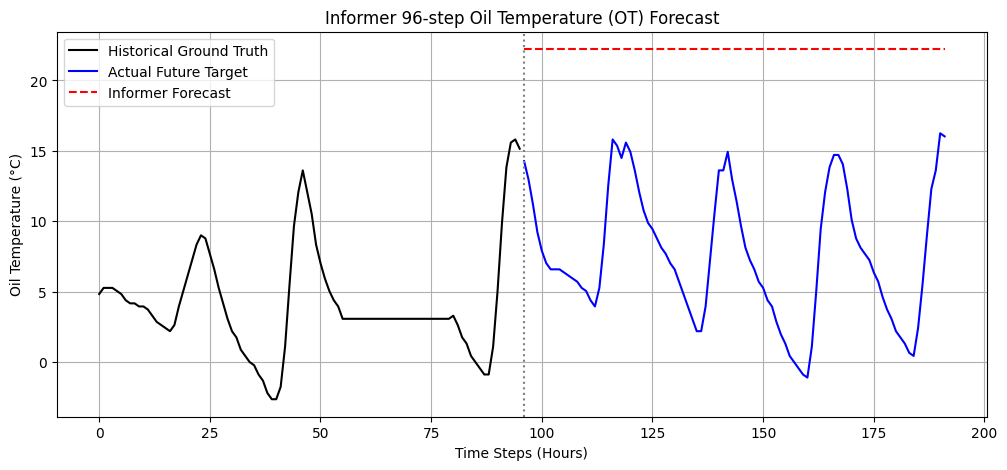

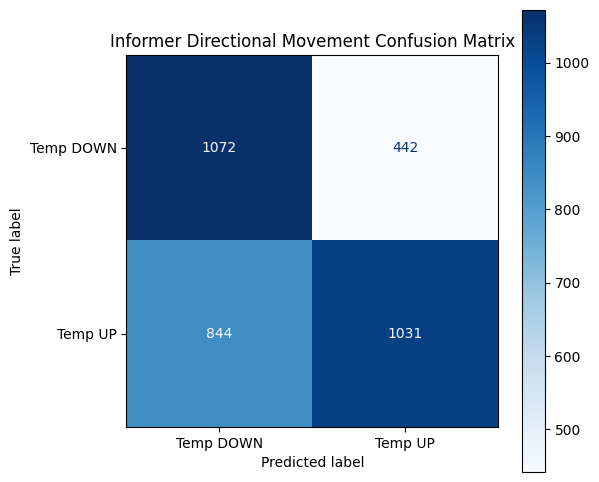

In [14]:
import os
import glob
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# =====================================================================
# 1. DOWNLOAD ETT DATASET VIA KAGGLEHUB
# =====================================================================
import kagglehub

path = kagglehub.dataset_download("alaaelmor/ettsmall")
csv_files = glob.glob(os.path.join(path, "*.csv"))
csv_path = csv_files[0] if csv_files else os.path.join(path, "ETTh1.csv")


# =====================================================================
# 2. DATASET DEFINITION
# =====================================================================
class ETTDataset(Dataset):
    def __init__(self, csv_file, seq_len=96, label_len=48, pred_len=96, mode='train'):
        self.seq_len = seq_len
        self.label_len = label_len
        self.pred_len = pred_len

        df = pd.read_csv(csv_file)
        if 'date' in df.columns:
            df = df.drop(columns=['date'])

        data = df.values.astype(np.float32)
        n = len(data)
        train_end, val_end = int(n * 0.7), int(n * 0.8)

        self.scaler = StandardScaler()
        self.scaler.fit(data[:train_end])
        data = self.scaler.transform(data)

        if mode == 'train':
            self.data = data[:train_end]
        elif mode == 'val':
            self.data = data[train_end - seq_len : val_end]
        else:
            self.data = data[val_end - seq_len :]

    def __len__(self):
        return len(self.data) - self.seq_len - self.pred_len + 1

    def __getitem__(self, index):
        s_begin = index
        s_end = s_begin + self.seq_len
        r_begin = s_end - self.label_len
        r_end = r_begin + self.label_len + self.pred_len

        seq_x = self.data[s_begin:s_end]
        seq_y = self.data[r_begin:r_end]
        return torch.tensor(seq_x, dtype=torch.float32), torch.tensor(seq_y, dtype=torch.float32)


# =====================================================================
# 3. INFORMER ARCHITECTURE MODULES
# =====================================================================

class ProbSparseAttention(nn.Module):
    """Approximate ProbSparse Self-Attention used in Informer."""

    def __init__(self, d_model, n_heads, factor=5):
        super().__init__()

        if d_model % n_heads != 0:
            raise ValueError("d_model must be divisible by n_heads")

        self.n_heads = n_heads
        self.d_k = d_model // n_heads
        self.factor = factor

        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)

    def forward(self, queries, keys, values):
        B, L_Q, _ = queries.shape
        _, L_K, _ = keys.shape

        Q = self.q_proj(queries).view(
            B, L_Q, self.n_heads, self.d_k
        ).transpose(1, 2)

        K = self.k_proj(keys).view(
            B, L_K, self.n_heads, self.d_k
        ).transpose(1, 2)

        V = self.v_proj(values).view(
            B, L_K, self.n_heads, self.d_k
        ).transpose(1, 2)

        # Number of sampled keys and selected queries
        sample_k = min(
            self.factor * int(np.ceil(np.log(L_K + 1))), L_K
        )
        n_top = min(
            self.factor * int(np.ceil(np.log(L_Q + 1))), L_Q
        )

        # Sample keys for each query
        sample_indices = torch.randint(
            L_K, (B, self.n_heads, L_Q, sample_k),
            device=queries.device
        )

        K_expanded = K.unsqueeze(2).expand(
            B, self.n_heads, L_Q, L_K, self.d_k
        )

        sampled_K = torch.gather(
            K_expanded,
            3,
            sample_indices.unsqueeze(-1).expand(
                B, self.n_heads, L_Q, sample_k, self.d_k
            )
        )

        # Estimate query sparsity
        sampled_scores = (
            Q.unsqueeze(3) * sampled_K
        ).sum(dim=-1) / math.sqrt(self.d_k)

        sparsity = (
            sampled_scores.max(dim=-1).values
            - sampled_scores.mean(dim=-1)
        )

        # Select the most important queries
        top_indices = sparsity.topk(n_top, dim=-1).indices

        Q_top = torch.gather(
            Q,
            2,
            top_indices.unsqueeze(-1).expand(
                B, self.n_heads, n_top, self.d_k
            )
        )

        # Attention only for selected queries
        scores = torch.matmul(
            Q_top, K.transpose(-2, -1)
        ) / math.sqrt(self.d_k)

        attention = torch.softmax(scores, dim=-1)
        context_top = torch.matmul(attention, V)

        # Mean context for queries not selected
        context = V.mean(dim=2, keepdim=True).expand(
            B, self.n_heads, L_Q, self.d_k
        ).clone()

        context.scatter_(
            2,
            top_indices.unsqueeze(-1).expand(
                B, self.n_heads, n_top, self.d_k
            ),
            context_top
        )

        out = context.transpose(1, 2).contiguous().view(
            B, L_Q, -1
        )

        return self.out_proj(out)


class InformerEncoderLayer(nn.Module):
    """Encoder layer with ProbSparse Attention and Distilling Conv Pooling."""
    def __init__(self, d_model, n_heads):
        super(InformerEncoderLayer, self).__init__()
        self.attn = ProbSparseAttention(d_model, n_heads)
        self.norm1 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_model * 4),
            nn.GELU(),
            nn.Linear(d_model * 4, d_model)
        )
        self.norm2 = nn.LayerNorm(d_model)
        # Distilling layer (Max Pool along temporal dimension)
        self.distill = nn.Conv1d(d_model, d_model, kernel_size=3, padding=1, stride=2)

    def forward(self, x):
        x = x + self.attn(x, x, x)
        x = self.norm1(x)
        x = x + self.ffn(x)
        x = self.norm2(x)
        # Apply distilling pooling
        x_distilled = self.distill(x.permute(0, 2, 1)).permute(0, 2, 1)
        return x_distilled


class Informer(nn.Module):
    """Simplified Informer Model for Multi-Step Forecasting."""
    def __init__(self, seq_len, label_len, pred_len, enc_in, dec_in, c_out, d_model=64, n_heads=4):
      super(Informer, self).__init__()

      if n_heads <= 0:
          raise ValueError("n_heads must be positive")

      if d_model % n_heads != 0:
          raise ValueError("d_model must be divisible by n_heads")

      self.seq_len = seq_len
      self.label_len = label_len
      self.pred_len = pred_len

      self.enc_embedding = nn.Linear(enc_in, d_model)
      self.dec_embedding = nn.Linear(dec_in, d_model)

      self.encoder = InformerEncoderLayer(d_model, n_heads)

      self.cross_attention = nn.MultiheadAttention(
          d_model, n_heads, batch_first=True
      )

      self.norm = nn.LayerNorm(d_model)
      self.projection = nn.Linear(d_model, c_out)

    def forward(self, x_enc, x_dec):
      enc_out = self.enc_embedding(x_enc)
      enc_out = self.encoder(enc_out)

      dec_out = self.dec_embedding(x_dec)

      cross_out, _ = self.cross_attention(
          dec_out, enc_out, enc_out
      )

      dec_out = self.norm(dec_out + cross_out)

      out = self.projection(dec_out)

      return out[:, -self.pred_len:, :]


# =====================================================================
# 4. TRAINING & EVALUATION PIPELINE
# =====================================================================
def main():
    SEQ_LEN, LABEL_LEN, PRED_LEN = 96, 48, 96
    BATCH_SIZE, EPOCHS, LEARNING_RATE = 32, 3, 0.001
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    train_dataset = ETTDataset(csv_path, SEQ_LEN, LABEL_LEN, PRED_LEN, mode='train')
    val_dataset = ETTDataset(csv_path, SEQ_LEN, LABEL_LEN, PRED_LEN, mode='val')
    test_dataset = ETTDataset(csv_path, SEQ_LEN, LABEL_LEN, PRED_LEN, mode='test')

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    num_features = train_dataset.data.shape[1]

    model = Informer(
        seq_len=SEQ_LEN, label_len=LABEL_LEN, pred_len=PRED_LEN,
        enc_in=num_features, dec_in=num_features, c_out=num_features
    ).to(DEVICE)

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    print(f"Training Informer on {DEVICE}...")
    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_loss = 0.0
        for x_enc, x_y in train_loader:
            x_enc, x_y = x_enc.to(DEVICE), x_y.to(DEVICE)
            zeros = torch.zeros(x_enc.shape[0], PRED_LEN, num_features, device=DEVICE)
            x_dec = torch.cat([x_enc[:, -LABEL_LEN:, :], zeros], dim=1)

            optimizer.zero_grad()
            preds = model(x_enc, x_dec)
            loss = criterion(preds, x_y[:, -PRED_LEN:, :])
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] | Train MSE: {train_loss / len(train_loader):.4f}")

        # Validation
        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for x_enc, x_y in val_loader:
                x_enc = x_enc.to(DEVICE)
                x_y = x_y.to(DEVICE)

                zeros = torch.zeros(
                    x_enc.shape[0], PRED_LEN, num_features,
                    device=DEVICE
                )

                x_dec = torch.cat(
                    [x_enc[:, -LABEL_LEN:, :], zeros],
                    dim=1
                )

                preds = model(x_enc, x_dec)

                loss = criterion(
                    preds, x_y[:, -PRED_LEN:, :]
                )

                val_loss += loss.item()

        print(
            f"Validation MSE: {val_loss / len(val_loader):.4f}"
        )


    # --- Test Set Evaluation ---
    model.eval()
    all_preds, all_targets, all_inputs = [], [], []

    with torch.no_grad():
        for x_enc, x_y in test_loader:
            x_enc, x_y = x_enc.to(DEVICE), x_y.to(DEVICE)
            zeros = torch.zeros(x_enc.shape[0], PRED_LEN, num_features, device=DEVICE)
            x_dec = torch.cat([x_enc[:, -LABEL_LEN:, :], zeros], dim=1)

            preds = model(x_enc, x_dec)
            all_inputs.append(x_enc.cpu().numpy())
            all_preds.append(preds.cpu().numpy())
            all_targets.append(x_y[:, -PRED_LEN:, :].cpu().numpy())

    all_inputs = np.concatenate(all_inputs, axis=0)
    all_preds = np.concatenate(all_preds, axis=0)
    all_targets = np.concatenate(all_targets, axis=0)

    # Inverse Transform Target Feature (OT - Oil Temperature)
    ot_idx = -1
    std_ot = test_dataset.scaler.scale_[ot_idx]
    mean_ot = test_dataset.scaler.mean_[ot_idx]

    pred_ot = all_preds[:, :, ot_idx] * std_ot + mean_ot
    target_ot = all_targets[:, :, ot_idx] * std_ot + mean_ot
    input_ot = all_inputs[:, :, ot_idx] * std_ot + mean_ot

    # --- PLOT 1: FORECAST GRAPH ---
    sample_idx = 0
    plt.figure(figsize=(12, 5))
    plt.plot(range(0, SEQ_LEN), input_ot[sample_idx], label="Historical Ground Truth", color="black")
    plt.plot(range(SEQ_LEN, SEQ_LEN + PRED_LEN), target_ot[sample_idx], label="Actual Future Target", color="blue")
    plt.plot(range(SEQ_LEN, SEQ_LEN + PRED_LEN), pred_ot[sample_idx], label="Informer Forecast", color="red", linestyle="--")
    plt.axvline(x=SEQ_LEN, color="gray", linestyle=":")
    plt.title("Informer 96-step Oil Temperature (OT) Forecast")
    plt.xlabel("Time Steps (Hours)")
    plt.ylabel("Oil Temperature (°C)")
    plt.legend()
    plt.grid(True)
    plt.show()

    # --- PLOT 2: DIRECTIONAL CONFUSION MATRIX ---
    last_known = input_ot[:, -1]
    actual_direction = (target_ot[:, -1] > last_known).astype(int)
    pred_direction = (pred_ot[:, -1] > last_known).astype(int)

    cm = confusion_matrix(actual_direction, pred_direction)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Temp DOWN", "Temp UP"])

    fig, ax = plt.subplots(figsize=(6, 6))
    disp.plot(cmap=plt.cm.Blues, ax=ax)
    plt.title("Informer Directional Movement Confusion Matrix")
    plt.show()


if __name__ == "__main__":
    main()

ETS FORMER (EXPONENTIAL SMOOTHENING TRANSFORMER)

Using Colab cache for faster access to the 'ettsmall' dataset.
Path to dataset files: /kaggle/input/ettsmall
Training ETSformer on cuda...
Epoch [01/03] | Train MSE: 0.3763
Validation MSE: 0.3611
Epoch [02/03] | Train MSE: 0.2520
Validation MSE: 0.3122
Epoch [03/03] | Train MSE: 0.2235
Validation MSE: 0.3192


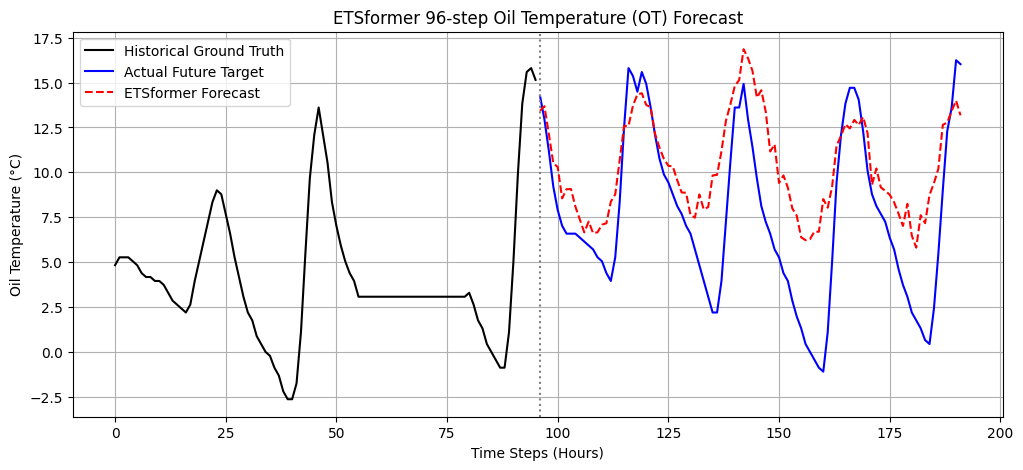

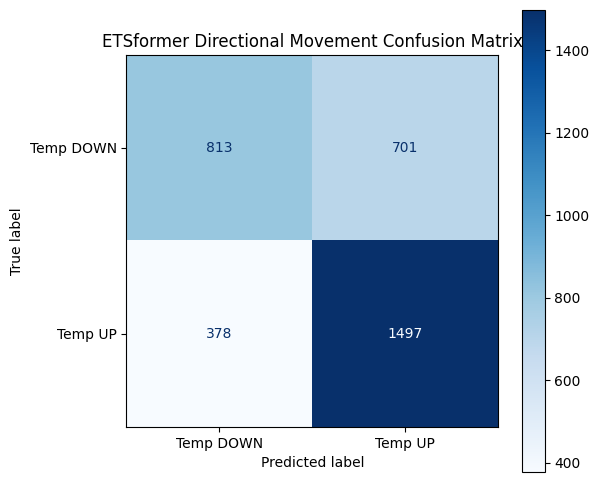

In [15]:
import os
import glob
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# =====================================================================
# 1. DOWNLOAD ETT DATASET VIA KAGGLEHUB
# =====================================================================
import kagglehub

path = kagglehub.dataset_download("alaaelmor/ettsmall")
print("Path to dataset files:", path)

csv_files = glob.glob(os.path.join(path, "*.csv"))
csv_path = csv_files[0] if csv_files else os.path.join(path, "ETTh1.csv")


# =====================================================================
# 2. DATASET DEFINITION
# =====================================================================
class ETTDataset(Dataset):
    def __init__(self, csv_file, seq_len=96, label_len=48, pred_len=96, mode='train'):
        self.seq_len = seq_len
        self.label_len = label_len
        self.pred_len = pred_len

        df = pd.read_csv(csv_file)
        if 'date' in df.columns:
            df = df.drop(columns=['date'])

        data = df.values.astype(np.float32)
        n = len(data)
        train_end, val_end = int(n * 0.7), int(n * 0.8)

        self.scaler = StandardScaler()
        self.scaler.fit(data[:train_end])
        data = self.scaler.transform(data)

        if mode == 'train':
            self.data = data[:train_end]
        elif mode == 'val':
            self.data = data[train_end - seq_len : val_end]
        else:
            self.data = data[val_end - seq_len :]

    def __len__(self):
        return len(self.data) - self.seq_len - self.pred_len + 1

    def __getitem__(self, index):
        s_begin = index
        s_end = s_begin + self.seq_len
        r_begin = s_end - self.label_len
        r_end = r_begin + self.label_len + self.pred_len

        seq_x = self.data[s_begin:s_end]
        seq_y = self.data[r_begin:r_end]
        return torch.tensor(seq_x, dtype=torch.float32), torch.tensor(seq_y, dtype=torch.float32)


# =====================================================================
# 3. ETSFORMER MODULES (Exponential Smoothing & Frequency Attention)
# =====================================================================

class TransformLayer(nn.Module):
    """Learns growth and seasonal transforms via Fourier domain mapping."""
    def __init__(self, d_model, K=8):
        super(TransformLayer, self).__init__()
        self.K = K
        self.d_model = d_model

    def forward(self, x):
        B, L, D = x.shape
        x_ft = torch.fft.rfft(x, dim=1)  # Frequency domain representation

        # Select top K frequencies
        amplitude = torch.abs(x_ft)
        _, top_k_idx = torch.topk(amplitude, min(self.K, x_ft.shape[1]), dim=1)

        # Zero out irrelevant frequencies (Smoothing filter)
        mask = torch.zeros_like(x_ft, dtype=torch.bool)
        mask.scatter_(1, top_k_idx, True)
        x_ft_filtered = x_ft * mask

        # Inverse FFT back to time domain
        return torch.fft.irfft(x_ft_filtered, n=L, dim=1)


class ExponentialSmoothingLayer(nn.Module):
    """Applies dampening exponential smoothing for Level and Trend tracking."""
    def __init__(self, d_model):
        super(ExponentialSmoothingLayer, self).__init__()
        self.alpha = nn.Parameter(torch.randn(d_model))
        self.beta = nn.Parameter(torch.randn(d_model))

    def forward(self, x):
        B, L, D = x.shape
        alpha = torch.sigmoid(self.alpha)
        beta = torch.sigmoid(self.beta)
        level = x.new_zeros(B, D)
        growth = x.new_zeros(B, D)

        levels, growths = [], []
        for t in range(L):
            x_t = x[:, t, :]
            next_level = alpha * x_t + (1 - alpha) * (level + growth)
            next_growth = beta * (next_level - level) + (1 - beta) * growth
            level, growth = next_level, next_growth
            levels.append(level.unsqueeze(1))
            growths.append(growth.unsqueeze(1))

        return torch.cat(levels, dim=1), torch.cat(growths, dim=1)


class ETSformerEncoderLayer(nn.Module):
    """ETSformer Encoder: Separates components into Level/Trend and Seasonality."""
    def __init__(self, d_model, K=8):
        super(ETSformerEncoderLayer, self).__init__()
        self.transform = TransformLayer(d_model, K=K)
        self.ets = ExponentialSmoothingLayer(d_model)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_model * 2),
            nn.GELU(),
            nn.Linear(d_model * 2, d_model)
        )

    def forward(self, x):
        # 1. Fourier Frequency Decomposition (Seasonality)
        season = self.transform(x)
        res = x - season

        # 2. Exponential Smoothing (Level and Growth)
        level, growth = self.ets(res)

        # 3. Residual FFN Pass
        res = self.norm1(res)
        res = res + self.ffn(res)
        res = self.norm2(res)

        return res, level, growth, season


class ETSformer(nn.Module):
    """ETSformer Architecture for Time Series Forecasting."""
    def __init__(self, seq_len, pred_len, enc_in, c_out, d_model=64, K=8, e_layers=2):
        super(ETSformer, self).__init__()
        self.seq_len = seq_len
        self.pred_len = pred_len

        self.enc_embedding = nn.Linear(enc_in, d_model)
        self.encoder_layers = nn.ModuleList([
            ETSformerEncoderLayer(d_model, K=K) for _ in range(e_layers)
        ])

        # Projections across temporal dimensions
        self.head_level = nn.Linear(1, pred_len)
        self.head_growth = nn.Linear(1, pred_len)
        self.head_season = nn.Linear(seq_len, pred_len)
        self.head_residual = nn.Linear(seq_len, pred_len)

        self.projection = nn.Linear(d_model, c_out)

    def forward(self, x_enc, x_dec=None):
        res = self.enc_embedding(x_enc)

        total_level = 0
        total_growth = 0
        total_season = 0

        # Stacked ETS Encoder layers
        for layer in self.encoder_layers:
            res, level, growth, season = layer(res)
            total_level = total_level + level[:, -1:, :]   # [B, 1, d_model]
            total_growth = total_growth + growth[:, -1:, :] # [B, 1, d_model]
            total_season = total_season + season            # [B, seq_len, d_model]


        # Project level and growth
        out_level = self.head_level(
            total_level.permute(0, 2, 1)
        ).permute(0, 2, 1)

        out_growth = self.head_growth(
            total_growth.permute(0, 2, 1)
        ).permute(0, 2, 1)

        # Project seasonality
        out_season = self.head_season(
            total_season.permute(0, 2, 1)
        ).permute(0, 2, 1)

        # Use the final residual representation
        out_residual = self.head_residual(
            res.permute(0, 2, 1)
        ).permute(0, 2, 1)

        # Combine all components
        forecast = (
            out_level
            + out_growth
            + out_season
            + out_residual
        )

        output = self.projection(forecast)

        return output


# =====================================================================
# 4. TRAINING & EVALUATION PIPELINE
# =====================================================================
def main():
    SEQ_LEN, LABEL_LEN, PRED_LEN = 96, 48, 96
    BATCH_SIZE, EPOCHS, LEARNING_RATE = 32, 3, 0.001
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    train_dataset = ETTDataset(csv_path, SEQ_LEN, LABEL_LEN, PRED_LEN, mode='train')
    val_dataset = ETTDataset(csv_path, SEQ_LEN, LABEL_LEN, PRED_LEN, mode='val')
    test_dataset = ETTDataset(csv_path, SEQ_LEN, LABEL_LEN, PRED_LEN, mode='test')

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    num_features = train_dataset.data.shape[1]

    model = ETSformer(
        seq_len=SEQ_LEN, pred_len=PRED_LEN,
        enc_in=num_features, c_out=num_features,
        d_model=64, K=8, e_layers=2
    ).to(DEVICE)

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    print(f"Training ETSformer on {DEVICE}...")
    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_loss = 0.0
        for x_enc, x_y in train_loader:
            x_enc, x_y = x_enc.to(DEVICE), x_y.to(DEVICE)

            optimizer.zero_grad()
            preds = model(x_enc)
            loss = criterion(preds, x_y[:, -PRED_LEN:, :])
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] | Train MSE: {train_loss / len(train_loader):.4f}")
        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for x_enc, x_y in val_loader:
                x_enc = x_enc.to(DEVICE)
                x_y = x_y.to(DEVICE)

                preds = model(x_enc)

                loss = criterion(
                    preds,
                    x_y[:, -PRED_LEN:, :]
                )

                val_loss += loss.item()

        print(f"Validation MSE: {val_loss / len(val_loader):.4f}")

    # --- Test Set Evaluation ---
    model.eval()
    all_preds, all_targets, all_inputs = [], [], []

    with torch.no_grad():
        for x_enc, x_y in test_loader:
            x_enc, x_y = x_enc.to(DEVICE), x_y.to(DEVICE)

            preds = model(x_enc)
            all_inputs.append(x_enc.cpu().numpy())
            all_preds.append(preds.cpu().numpy())
            all_targets.append(x_y[:, -PRED_LEN:, :].cpu().numpy())

    all_inputs = np.concatenate(all_inputs, axis=0)
    all_preds = np.concatenate(all_preds, axis=0)
    all_targets = np.concatenate(all_targets, axis=0)

    # Inverse Transform Target Feature (OT - Oil Temperature)
    ot_idx = -1
    std_ot = test_dataset.scaler.scale_[ot_idx]
    mean_ot = test_dataset.scaler.mean_[ot_idx]

    pred_ot = all_preds[:, :, ot_idx] * std_ot + mean_ot
    target_ot = all_targets[:, :, ot_idx] * std_ot + mean_ot
    input_ot = all_inputs[:, :, ot_idx] * std_ot + mean_ot

    # --- PLOT 1: FORECAST GRAPH ---
    sample_idx = 0
    plt.figure(figsize=(12, 5))
    plt.plot(range(0, SEQ_LEN), input_ot[sample_idx], label="Historical Ground Truth", color="black")
    plt.plot(range(SEQ_LEN, SEQ_LEN + PRED_LEN), target_ot[sample_idx], label="Actual Future Target", color="blue")
    plt.plot(range(SEQ_LEN, SEQ_LEN + PRED_LEN), pred_ot[sample_idx], label="ETSformer Forecast", color="red", linestyle="--")
    plt.axvline(x=SEQ_LEN, color="gray", linestyle=":")
    plt.title("ETSformer 96-step Oil Temperature (OT) Forecast")
    plt.xlabel("Time Steps (Hours)")
    plt.ylabel("Oil Temperature (°C)")
    plt.legend()
    plt.grid(True)
    plt.show()

    # --- PLOT 2: DIRECTIONAL CONFUSION MATRIX ---
    last_known = input_ot[:, -1]
    actual_direction = (target_ot[:, -1] > last_known).astype(int)
    pred_direction = (pred_ot[:, -1] > last_known).astype(int)

    cm = confusion_matrix(actual_direction, pred_direction)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Temp DOWN", "Temp UP"])

    fig, ax = plt.subplots(figsize=(6, 6))
    disp.plot(cmap=plt.cm.Blues, ax=ax)
    plt.title("ETSformer Directional Movement Confusion Matrix")
    plt.show()


if __name__ == "__main__":
    main()

CROSS FORMER

Using Colab cache for faster access to the 'ettsmall' dataset.
Path to dataset files: /kaggle/input/ettsmall
Training Crossformer on cuda...
Epoch [01/03] | Train MSE: 0.2714
Validation MSE: 0.4047
Epoch [02/03] | Train MSE: 0.1964
Validation MSE: 1.1371
Epoch [03/03] | Train MSE: 0.1678
Validation MSE: 0.8804


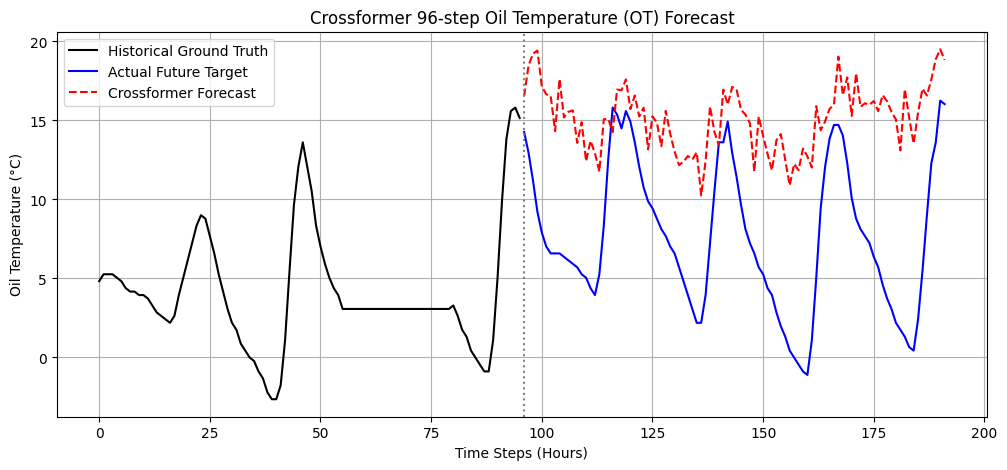

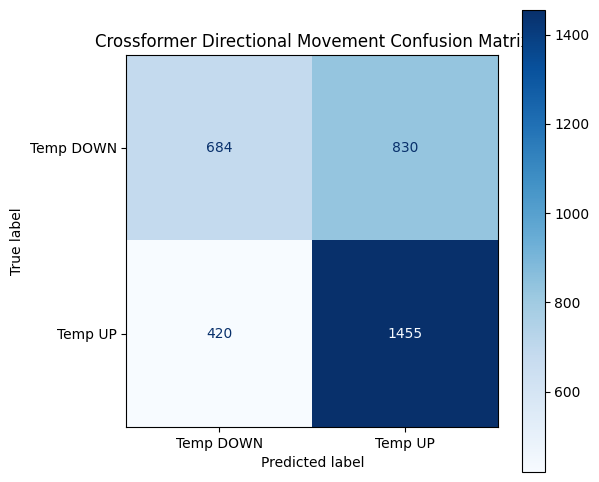

In [16]:
import os
import glob
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# =====================================================================
# 1. DOWNLOAD ETT DATASET VIA KAGGLEHUB
# =====================================================================
import kagglehub

path = kagglehub.dataset_download("alaaelmor/ettsmall")
print("Path to dataset files:", path)

csv_files = glob.glob(os.path.join(path, "*.csv"))
csv_path = csv_files[0] if csv_files else os.path.join(path, "ETTh1.csv")


# =====================================================================
# 2. DATASET DEFINITION
# =====================================================================
class ETTDataset(Dataset):
    def __init__(self, csv_file, seq_len=96, label_len=48, pred_len=96, mode='train'):
        self.seq_len = seq_len
        self.label_len = label_len
        self.pred_len = pred_len

        df = pd.read_csv(csv_file)
        if 'date' in df.columns:
            df = df.drop(columns=['date'])

        data = df.values.astype(np.float32)
        n = len(data)
        train_end, val_end = int(n * 0.7), int(n * 0.8)

        self.scaler = StandardScaler()
        self.scaler.fit(data[:train_end])
        data = self.scaler.transform(data)

        if mode == 'train':
            self.data = data[:train_end]
        elif mode == 'val':
            self.data = data[train_end - seq_len : val_end]
        else:
            self.data = data[val_end - seq_len :]

    def __len__(self):
        return len(self.data) - self.seq_len - self.pred_len + 1

    def __getitem__(self, index):
        s_begin = index
        s_end = s_begin + self.seq_len
        r_begin = s_end - self.label_len
        r_end = r_begin + self.label_len + self.pred_len

        seq_x = self.data[s_begin:s_end]
        seq_y = self.data[r_begin:r_end]
        return torch.tensor(seq_x, dtype=torch.float32), torch.tensor(seq_y, dtype=torch.float32)


# =====================================================================
# 3. CROSSFORMER MODULES (Dimension-Segment Embedding & TSA Block)
# =====================================================================

class DSWEmbedding(nn.Module):
    """Dimension-Segment-Wise (DSW) Embedding."""
    def __init__(self, seg_len, d_model):
        super(DSWEmbedding, self).__init__()
        self.seg_len = seg_len
        self.linear = nn.Linear(seg_len, d_model)

    def forward(self, x):
        B, L, D = x.shape
        x = x.permute(0, 2, 1).unfold(dimension=-1, size=self.seg_len, step=self.seg_len)
        out = self.linear(x)
        return out


class TwoStageAttention(nn.Module):
    """Two-Stage Attention (TSA) Layer: Cross-Time & Cross-Dimension."""
    def __init__(self, n_heads, d_model, d_ff=128):
        super(TwoStageAttention, self).__init__()

        if n_heads <= 0:
          raise ValueError("n_heads must be positive")

        if d_model % n_heads != 0:
          raise ValueError("d_model must be divisible by n_heads")

        self.time_attn = nn.MultiheadAttention(embed_dim=d_model, num_heads=n_heads, batch_first=True)
        self.dim_attn = nn.MultiheadAttention(embed_dim=d_model, num_heads=n_heads, batch_first=True)

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)

        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Linear(d_ff, d_model)
        )

    def forward(self, x):
        B, D, N, d_model = x.shape

        # Stage 1: Cross-Time Attention
        x_time = x.view(B * D, N, d_model)
        attn_time, _ = self.time_attn(x_time, x_time, x_time)
        x_time = self.norm1(x_time + attn_time).view(B, D, N, d_model)

        # Stage 2: Cross-Dimension Attention
        x_dim = x_time.permute(0, 2, 1, 3).contiguous().view(B * N, D, d_model)
        attn_dim, _ = self.dim_attn(x_dim, x_dim, x_dim)
        x_dim = self.norm2(x_dim + attn_dim).view(B, N, D, d_model).permute(0, 2, 1, 3)

        # Feed-Forward Stage
        out = self.norm3(x_dim + self.ffn(x_dim))
        return out


class Crossformer(nn.Module):
    """Crossformer Architecture for Multivariate Time Series Forecasting."""
    def __init__(self, seq_len, pred_len, in_dim, seg_len=16, d_model=64, n_heads=4, depth=2):
        super(Crossformer, self).__init__()
        self.seq_len = seq_len
        self.pred_len = pred_len
        self.seg_len = seg_len
        self.pad_len = (seg_len - (seq_len % seg_len)) % seg_len

        effective_seq_len = seq_len + self.pad_len
        self.num_seg = effective_seq_len // seg_len

        self.embedding = DSWEmbedding(seg_len, d_model)
        self.pos_emb = nn.Parameter(torch.randn(1, in_dim, self.num_seg, d_model))

        self.layers = nn.ModuleList([
            TwoStageAttention(n_heads=n_heads, d_model=d_model) for _ in range(depth)
        ])

        self.head = nn.Linear(self.num_seg * d_model, pred_len)

    def forward(self, x_enc, x_dec=None):
        B, L, D = x_enc.shape

        if self.pad_len > 0:
            pad = x_enc.new_zeros(B, self.pad_len, D)
            x_enc = torch.cat([x_enc, pad], dim=1)

        x_emb = self.embedding(x_enc) + self.pos_emb

        for layer in self.layers:
            x_emb = layer(x_emb)

        x_flat = x_emb.view(B, D, -1)
        out = self.head(x_flat).permute(0, 2, 1)
        return out


# =====================================================================
# 4. TRAINING & EVALUATION PIPELINE
# =====================================================================
def main():
    SEQ_LEN, LABEL_LEN, PRED_LEN = 96, 48, 96
    BATCH_SIZE, EPOCHS, LEARNING_RATE = 32, 3, 0.001
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    train_dataset = ETTDataset(csv_path, SEQ_LEN, LABEL_LEN, PRED_LEN, mode='train')
    val_dataset = ETTDataset(csv_path, SEQ_LEN, LABEL_LEN, PRED_LEN, mode='val')
    test_dataset = ETTDataset(csv_path, SEQ_LEN, LABEL_LEN, PRED_LEN, mode='test')

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    num_features = train_dataset.data.shape[1]

    model = Crossformer(
        seq_len=SEQ_LEN, pred_len=PRED_LEN, in_dim=num_features,
        seg_len=16, d_model=64, n_heads=4, depth=2
    ).to(DEVICE)

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    print(f"Training Crossformer on {DEVICE}...")
    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_loss = 0.0
        for x_enc, x_y in train_loader:
            x_enc, x_y = x_enc.to(DEVICE), x_y.to(DEVICE)

            optimizer.zero_grad()
            preds = model(x_enc)
            loss = criterion(preds, x_y[:, -PRED_LEN:, :])
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] | Train MSE: {train_loss / len(train_loader):.4f}")
        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for x_enc, x_y in val_loader:
                x_enc = x_enc.to(DEVICE)
                x_y = x_y.to(DEVICE)

                preds = model(x_enc)

                loss = criterion(
                    preds,
                    x_y[:, -PRED_LEN:, :]
                )

                val_loss += loss.item()

        print(f"Validation MSE: {val_loss / len(val_loader):.4f}")

    # --- Test Set Evaluation ---
    model.eval()
    all_preds, all_targets, all_inputs = [], [], []

    with torch.no_grad():
        for x_enc, x_y in test_loader:
            x_enc, x_y = x_enc.to(DEVICE), x_y.to(DEVICE)

            preds = model(x_enc)
            all_inputs.append(x_enc.cpu().numpy())
            all_preds.append(preds.cpu().numpy())
            all_targets.append(x_y[:, -PRED_LEN:, :].cpu().numpy())

    all_inputs = np.concatenate(all_inputs, axis=0)
    all_preds = np.concatenate(all_preds, axis=0)
    all_targets = np.concatenate(all_targets, axis=0)

    # Inverse Transform Target Feature (OT - Oil Temperature)
    ot_idx = -1
    std_ot = test_dataset.scaler.scale_[ot_idx]
    mean_ot = test_dataset.scaler.mean_[ot_idx]

    pred_ot = all_preds[:, :, ot_idx] * std_ot + mean_ot
    target_ot = all_targets[:, :, ot_idx] * std_ot + mean_ot
    input_ot = all_inputs[:, :, ot_idx] * std_ot + mean_ot

    # --- PLOT 1: FORECAST GRAPH ---
    sample_idx = 0
    plt.figure(figsize=(12, 5))
    plt.plot(range(0, SEQ_LEN), input_ot[sample_idx], label="Historical Ground Truth", color="black")
    plt.plot(range(SEQ_LEN, SEQ_LEN + PRED_LEN), target_ot[sample_idx], label="Actual Future Target", color="blue")
    plt.plot(range(SEQ_LEN, SEQ_LEN + PRED_LEN), pred_ot[sample_idx], label="Crossformer Forecast", color="red", linestyle="--")
    plt.axvline(x=SEQ_LEN, color="gray", linestyle=":")
    plt.title("Crossformer 96-step Oil Temperature (OT) Forecast")
    plt.xlabel("Time Steps (Hours)")
    plt.ylabel("Oil Temperature (°C)")
    plt.legend()
    plt.grid(True)
    plt.show()

    # --- PLOT 2: DIRECTIONAL CONFUSION MATRIX ---
    last_known = input_ot[:, -1]
    actual_direction = (target_ot[:, -1] > last_known).astype(int)
    pred_direction = (pred_ot[:, -1] > last_known).astype(int)

    cm = confusion_matrix(actual_direction, pred_direction)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Temp DOWN", "Temp UP"])

    fig, ax = plt.subplots(figsize=(6, 6))
    disp.plot(cmap=plt.cm.Blues, ax=ax)
    plt.title("Crossformer Directional Movement Confusion Matrix")
    plt.show()


if __name__ == "__main__":
    main()